# AnalystLab Africa – Week 4
## Consumer Complaint Trends and Response Intelligence: Bank of America (CFPB data, 2017–2023)

**Author:** *Charity Nduati*  |  **Programme:** AnalystLab Africa, Experience Lab Internship Programme  |  **Project:** Week 4, Consumer Complaint Trends and Response

---
### Notebook roadmap
1. Business understanding, research questions and hypotheses
2. Setup
3. Data loading and inspection
4. Data preparation (documented, validated, reproducible)
5. Exploratory data analysis
6. Statistical analysis (H1–H6)
7. Forecasting feasibility (business question 9)
8. Findings, limitations and alternative explanations
9. Reproducibility record

**How to run:** put `Consumer_Complaints_xlsx_-_Data.csv` (or the original `Consumer_Complaints.xlsx`) and `ConsumerComplaints_DataDictionary.csv` in `data/raw/`, then choose *Run All*. The raw files are never modified.

> **Important interpretation rule.** A complaint is an issue reported by a consumer. It does **not** establish misconduct or a regulatory violation. All results below describe recorded patterns and statistical association, not causes.

## 1. Business Understanding, Research Questions and Hypotheses

**Context.** The Consumer Financial Protection Bureau (CFPB) receives consumer complaints about financial products and forwards eligible complaints to the company for a response. This analysis uses **62,516 complaints about Bank of America** received by the CFPB between **1 May 2017 and 28 August 2023**.

**Scope note.** The supplied file has 12 fields and **no company-name column**, so the "Bank of America" label comes from the project brief and cannot be verified inside the data. The records are analysed as the project-provided Bank of America extract. Findings describe this extract only.

**Objective.** Describe complaint volumes, products, issues, recorded responses and forwarding intervals, and test whether the patterns observed differ across years, products and channels.

**Key data-meaning rules (from the data dictionary and project brief):**
- *Date submitted* = when the CFPB **received** the complaint. *Date received* = when the CFPB **sent** it to the company. Their difference is the **CFPB forwarding interval**, *not* the company's response or resolution time.
- A blank *Timely response?* is **not** "No". In the supplied records it belongs to complaints marked *In progress*.
- Missing *Sub-issue* and *Company public response* values have structural meanings and are handled accordingly (Section 4).

### Research questions and hypotheses

| ID | Research question | H0 (null) | H1 (alternative) | Planned test and effect size |
|---|---|---|---|---|
| **H1** | Did complaint volumes differ across the reporting years? | Monthly complaint counts have the same distribution in every full year (2018–2022) and show no monotonic trend | Counts differ across years / trend exists | Shapiro–Wilk (normality), Kruskal–Wallis + Holm-adjusted pairwise Mann–Whitney, Kendall's tau + Theil–Sen slope with block-bootstrap CI; ε² |
| **H2** | Has the product mix of complaints changed over time? | Product distribution is independent of year | Product mix depends on year | Chi-square test of independence, Cramér's V, adjusted residuals |
| **H3** | Do CFPB forwarding intervals vary across products, channels and years? | Forwarding-interval distributions are identical across groups | At least one group differs | Kruskal–Wallis, ε², Mann–Whitney (common-language effect size), stratified checks for confounding by channel |
| **H4** | Are recorded response categories associated with product (and issue)? | Response category is independent of product | Response category depends on product | Chi-square, Cramér's V, Wilson confidence intervals |
| **H5** | Has the share of "not timely" responses changed over time? | Not-timely share is equal across years | Share differs across years | Chi-square, Cramér's V, Wilson confidence intervals |
| **H6** | Has the composition of recorded response categories changed over time? | Response category is independent of year | Response category depends on year | Chi-square, Cramér's V, Kendall's tau on monthly monetary-relief share |

*Mapping to the earlier draft's questions: RQ1 (forwarding intervals by product) is H3a; RQ2 (response by product) is H4a; RQ3 (timely status by year) is H5; RQ4 (monotonic trend) is H1a, where Spearman's rho from the draft is reported next to Kendall's tau.*

**Significance level:** α = 0.05 per test. Because six primary hypotheses are tested, a Bonferroni-adjusted threshold of 0.05 / 6 ≈ 0.0083 is also reported. With about 62,000 records, even tiny differences are statistically significant, so **effect sizes** are used to judge practical importance.

**Business questions this notebook addresses:** Q1–Q8 directly; Q9 (forecasting) as a feasibility check; Q10 (dashboard / AI assistant) is a later deliverable and is outside this notebook's scope.

## 2. Setup

In [1]:
import os, glob, hashlib, itertools, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 12})
PAL = sns.color_palette("deep")
RANDOM_STATE = 42
ALPHA = 0.05
BONFERRONI_ALPHA = ALPHA / 6   # six primary hypotheses

for folder in ["data/raw", "data/processed", "images"]:
    os.makedirs(folder, exist_ok=True)

def save_fig(name):
    # Save the current figure to /images (for the repo and reports), then display it
    plt.tight_layout()
    plt.savefig(f"images/{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

# ---------- statistical helper functions ----------
def chi2_test(ct):
    # Chi-square test of independence with the assumption check and Cramer's V
    chi2, p, dof, expected = stats.chi2_contingency(ct)
    n = ct.values.sum()
    df_star = min(ct.shape) - 1
    v = np.sqrt(chi2 / (n * df_star))
    # Cohen's conventions (w = 0.1 / 0.3 / 0.5) rescaled for Cramer's V by the table size
    cuts = np.array([0.1, 0.3, 0.5]) / np.sqrt(df_star)
    label = ["negligible", "small", "medium", "large"][int((v >= cuts).sum())]
    return {"chi2": chi2, "p": p, "dof": dof, "n": int(n), "cramers_v": v, "v_label": label,
            "min_expected": expected.min(), "pct_cells_expected_lt5": (expected < 5).mean() * 100,
            "expected": expected}

def v_text(r):
    return f"Cramer's V = {r['cramers_v']:.3f} ({r['v_label']} effect)"

def adjusted_residuals(ct, expected):
    # Standardised (adjusted) residuals: |value| > 2 marks cells that differ notably from independence
    n = ct.values.sum()
    row = ct.sum(axis=1).values[:, None] / n
    col = ct.sum(axis=0).values[None, :] / n
    res = (ct.values - expected) / np.sqrt(expected * (1 - row) * (1 - col))
    return pd.DataFrame(res, index=ct.index, columns=ct.columns)

def wilson_ci(k, n, z=1.96):
    # 95% Wilson score interval for a proportion
    if n == 0:
        return (np.nan, np.nan)
    p = k / n
    denom = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / denom
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denom
    return centre - half, centre + half

def epsilon_squared(H, n):
    # Effect size for Kruskal-Wallis: 0.01 small, 0.06 medium, 0.14 large (rule of thumb)
    return H / (n - 1)

def cles(x, y):
    # Common-language effect size: P(X > Y) + 0.5 P(X = Y). 0.5 means no difference
    U, p = stats.mannwhitneyu(x, y, alternative="two-sided")
    return U / (len(x) * len(y)), p

def eps_label(e):
    # Conventional cut-offs for epsilon-squared: 0.01 small, 0.06 medium, 0.14 large
    return ["negligible", "small", "medium", "large"][int((e >= np.array([0.01, 0.06, 0.14])).sum())]

def holm_adjust(pvals):
    # Holm-Bonferroni adjusted p-values
    p = np.asarray(pvals, dtype=float)
    order = np.argsort(p)
    adj = np.empty_like(p)
    running = 0.0
    for rank, idx in enumerate(order):
        running = max(running, (len(p) - rank) * p[idx])
        adj[idx] = min(1.0, running)
    return adj

def block_bootstrap_slope(y, block=6, n_boot=1000, seed=RANDOM_STATE):
    # Theil-Sen slope with a moving-block bootstrap CI (keeps month-to-month autocorrelation)
    rng = np.random.default_rng(seed)
    n = len(y); t = np.arange(n)
    slope, intercept = stats.theilslopes(y, t)[:2]
    fitted = intercept + slope * t
    resid = y - fitted
    nb = int(np.ceil(n / block))
    out = []
    for _ in range(n_boot):
        starts = rng.integers(0, n, nb)
        idx = np.concatenate([(np.arange(s, s + block)) % n for s in starts])[:n]
        out.append(stats.theilslopes(fitted + resid[idx], t)[0])
    return slope, np.percentile(out, [2.5, 97.5])

def fmt_p(p):
    return "p < 0.001" if p < 0.001 else f"p = {p:.3f}"

RESULTS = []   # collects every test for the summary table in Section 6.7
def log_result(hyp, test, statistic, p, effect, conclusion):
    RESULTS.append({"hypothesis": hyp, "test": test, "statistic": statistic,
                    "p_value": p, "effect_size": effect, "conclusion": conclusion})

## 3. Data Loading and Inspection

In [2]:
REQUIRED = {"Complaint ID", "Date submitted", "Timely response?"}

def has_required_columns(path):
    try:
        if str(path).lower().endswith(".xlsx"):
            cols = pd.read_excel(path, sheet_name="Data", nrows=0).columns
        else:
            cols = pd.read_csv(path, nrows=0).columns
        return REQUIRED.issubset(cols)
    except Exception:
        return False

def find_file(kind="data"):
    # Look in data/raw first, then near the notebook, then common download folders
    folders = [Path("data/raw"), Path("."), Path(".."), Path.home() / "Downloads", Path.home() / "Desktop", Path.home() / "Documents"]
    for base in folders:
        if not base.exists():
            continue
        paths = list(base.glob("*.csv")) + list(base.glob("*.xlsx"))
        if base == Path("."):
            paths = list(base.rglob("*.csv")) + list(base.rglob("*.xlsx"))
        for p in paths:
            if "processed" in p.parts:
                continue
            if kind == "data" and has_required_columns(p):
                return p
            if kind == "dictionary" and "datadictionary" in p.name.lower().replace("_", ""):
                return p
    return None

# Optional: set the path yourself if the automatic search fails (use forward slashes), e.g.
# DATA_PATH = Path("C:/Users/you/Downloads/Consumer_Complaints.xlsx")
DATA_PATH = None
if DATA_PATH is None:
    DATA_PATH = find_file("data")
if DATA_PATH is None:
    try:  # Google Colab fallback
        from google.colab import files
        print("Upload the consumer complaints file (CSV or XLSX).")
        up = files.upload()
        DATA_PATH = Path(list(up.keys())[0])
    except ImportError:
        raise FileNotFoundError(
            "Could not find the complaints file.\n"
            f"This notebook is running in: {os.getcwd()}\n"
            "Fix: put the CSV/XLSX in a folder called data/raw inside that directory, or set DATA_PATH in this cell."
        )

# Keep the original, untouched, in data/raw/
if DATA_PATH.resolve().parent != Path("data/raw").resolve():
    import shutil; shutil.copy(DATA_PATH, "data/raw/")

if DATA_PATH.suffix.lower() == ".xlsx":
    df_raw = pd.read_excel(DATA_PATH, sheet_name="Data")
else:
    df_raw = pd.read_csv(DATA_PATH)

FILE_SHA256 = hashlib.sha256(Path(DATA_PATH).read_bytes()).hexdigest()
print(f"Loaded: {DATA_PATH}")
print(f"SHA-256 of the raw file (for the reproducibility record): {FILE_SHA256[:16]}...")

dict_path = find_file("dictionary")
if dict_path is not None:
    data_dictionary = pd.read_csv(dict_path, encoding="utf-8-sig")
    print()
    print("DATA DICTIONARY")
    display(data_dictionary)

Loaded: Consumer_Complaints.xlsx - Data.csv
SHA-256 of the raw file (for the reproducibility record): 4ea648e8df464f0d...

DATA DICTIONARY


,Field,Description
0,Complaint ID,The unique identification number for a complaint
1,Submitted via,How the complaint was submitted to the CFPB
2,Date submitted,The date the CFPB received the complaint
3,Date received,The date the CFPB sent the complaint to the co...
4,State,The state of the mailing address provided by t...
5,Product,The type of product the consumer identified in...
6,Sub-product,The type of sub-product the consumer identifie...
7,Issue,The issue the consumer identified in the compl...
8,Sub-issue,The sub-issue the consumer identified in the c...
9,Company public response,"The company's optional, public-facing response..."


### 3.1 First 10 rows and structure

In [3]:
display(df_raw.head(10))
print(f"Rows: {df_raw.shape[0]:,}   Columns: {df_raw.shape[1]}")
print()
df_raw.info()

,Complaint ID,Submitted via,Date submitted,Date received,State,Product,Sub-product,Issue,Sub-issue,Company public response,Company response to consumer,Timely response?
0,4848023,Referral,2021-10-24,2021-10-27,NY,Mortgage,Conventional home mortgage,Applying for a mortgage or refinancing an exis...,NaN,Company has responded to the consumer and the ...,Closed with explanation,Yes
1,3621464,Web,2020-04-24,2020-04-24,FL,"Money transfer, virtual currency, or money ser...",Refund anticipation check,Lost or stolen check,NaN,Company has responded to the consumer and the ...,Closed with monetary relief,Yes
2,5818349,Web,2022-07-27,2022-07-27,CA,"Credit reporting, credit repair services, or o...",Credit reporting,Incorrect information on your report,Account information incorrect,Company has responded to the consumer and the ...,Closed with explanation,Yes
3,7233015,Referral,2023-07-10,2023-07-11,CA,Credit card or prepaid card,General-purpose prepaid card,Problem getting a card or closing an account,"Trouble getting, activating, or registering a ...",NaN,In progress,NaN
4,5820224,Referral,2022-07-27,2022-07-28,VA,Credit card or prepaid card,General-purpose credit card or charge card,Closing your account,Company closed your account,Company has responded to the consumer and the ...,Closed with explanation,Yes
5,6237961,Web,2022-11-23,2022-11-23,CA,Credit card or prepaid card,General-purpose credit card or charge card,Getting a credit card,Card opened as result of identity theft or fraud,Company has responded to the consumer and the ...,Closed with explanation,Yes
6,4348292,Web,2021-05-04,2021-05-04,TX,Checking or savings account,Checking account,Closing an account,Funds not received from closed account,Company has responded to the consumer and the ...,Closed with monetary relief,Yes
7,4090544,Web,2021-01-24,2021-01-24,CA,"Credit reporting, credit repair services, or o...",Credit reporting,Incorrect information on your report,Account status incorrect,Company has responded to the consumer and the ...,Closed with explanation,Yes
8,5337082,Web,2022-03-18,2022-03-18,TX,Credit card or prepaid card,General-purpose credit card or charge card,Fees or interest,Problem with fees,Company has responded to the consumer and the ...,Closed with monetary relief,Yes
9,6203657,Web,2022-11-14,2022-11-14,VA,Checking or savings account,Other banking product or service,Closing an account,Funds not received from closed account,Company has responded to the consumer and the ...,Closed with explanation,Yes


Rows: 62,516   Columns: 12

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 62516 entries, 0 to 62515
Data columns (total 12 columns):
 #   Column                        Non-Null Count  Dtype 
---  ------                        --------------  ----- 
 0   Complaint ID                  62516 non-null  int64 
 1   Submitted via                 62516 non-null  object
 2   Date submitted                62516 non-null  object
 3   Date received                 62516 non-null  object
 4   State                         62516 non-null  object
 5   Product                       62516 non-null  object
 6   Sub-product                   62509 non-null  object
 7   Issue                         62516 non-null  object
 8   Sub-issue                     51658 non-null  object
 9   Company public response       60341 non-null  object
 10  Company response to consumer  62516 non-null  object
 11  Timely response?              61022 non-null  object
dtypes: int64(1), object(11)
memory usage: 5.7+ MB


### 3.2 Uniqueness, duplicates, missing values and date validity

In [4]:
print("COMPLAINT ID (candidate primary key)")
print(f"  Unique IDs         : {df_raw['Complaint ID'].is_unique}")
print(f"  Duplicate IDs      : {df_raw['Complaint ID'].duplicated().sum()}")
print(f"  Fully duplicated rows: {df_raw.duplicated().sum()}")
print(f"  Duplicates ignoring ID: {df_raw.drop(columns='Complaint ID').duplicated().sum()}")

print()
print("MISSING VALUES")
missing = pd.DataFrame({"missing_count": df_raw.isna().sum(),
                        "missing_pct": (df_raw.isna().mean() * 100).round(2)}).sort_values("missing_count", ascending=False)
display(missing)

print("DATE VALIDITY (strict YYYY-MM-DD parsing)")
for col in ["Date submitted", "Date received"]:
    parsed = pd.to_datetime(df_raw[col], format="%Y-%m-%d", errors="coerce")
    print(f"  {col:15s}: unparseable = {parsed.isna().sum()},  min = {parsed.min().date()},  max = {parsed.max().date()}")

print()
print("CATEGORICAL COLUMNS: distinct values")
cat_cols = ["Submitted via", "State", "Product", "Sub-product", "Issue", "Sub-issue",
            "Company public response", "Company response to consumer", "Timely response?"]
display(pd.DataFrame({"distinct_values": [df_raw[c].nunique() for c in cat_cols],
                      "most_common": [df_raw[c].mode().iloc[0] for c in cat_cols]}, index=cat_cols))

COMPLAINT ID (candidate primary key)
  Unique IDs         : True
  Duplicate IDs      : 0
  Fully duplicated rows: 0
  Duplicates ignoring ID: 1494

MISSING VALUES


,missing_count,missing_pct
Sub-issue,10858,17.37
Company public response,2175,3.48
Timely response?,1494,2.39
Sub-product,7,0.01
Complaint ID,0,0.00
Submitted via,0,0.00
Date submitted,0,0.00
Date received,0,0.00
State,0,0.00
Product,0,0.00


DATE VALIDITY (strict YYYY-MM-DD parsing)
  Date submitted : unparseable = 0,  min = 2017-05-01,  max = 2023-08-28
  Date received  : unparseable = 0,  min = 2017-05-01,  max = 2023-08-28

CATEGORICAL COLUMNS: distinct values


,distinct_values,most_common
Submitted via,7,Web
State,51,CA
Product,9,Checking or savings account
Sub-product,46,Checking account
Issue,76,Managing an account
Sub-issue,158,Deposits and withdrawals
Company public response,6,Company has responded to the consumer and the ...
Company response to consumer,5,Closed with explanation
Timely response?,2,Yes


**A note on the 1,494 "duplicates ignoring ID".** The Complaint ID is unique and no row is fully duplicated, so there are **no true duplicate records**. However, 1,494 records match an earlier record on all eleven other fields (1,290 groups, mostly pairs). The file has only coarse fields (no time of day, no consumer identifier, no narrative), so several consumers filing similar complaints in the same state on the same day will look identical. Many of these are web complaints about credit reporting, account management or card issues. Because each has its own Complaint ID, they are **kept as separate complaints, flagged** (`flag_near_duplicate`), and a **sensitivity analysis in Section 6.8** shows the conclusions do not depend on them.

**Visualization 1 – Missing values.** Four columns have gaps. These are not random: the pattern of missingness has a meaning that is investigated in Section 4.

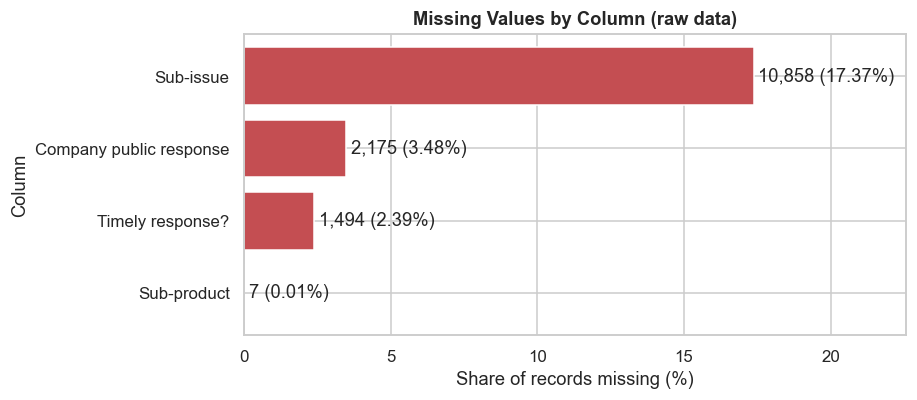

In [5]:
miss_plot = missing[missing["missing_count"] > 0].sort_values("missing_pct")
fig, ax = plt.subplots(figsize=(8.5, 3.8))
bars = ax.barh(miss_plot.index, miss_plot["missing_pct"], color=PAL[3])
ax.bar_label(bars, labels=[f"{n:,} ({p}%)" for n, p in zip(miss_plot["missing_count"], miss_plot["missing_pct"])], padding=3)
ax.set_title("Missing Values by Column (raw data)")
ax.set_xlabel("Share of records missing (%)")
ax.set_ylabel("Column")
ax.set_xlim(0, miss_plot["missing_pct"].max() * 1.3)
save_fig("01_missing_values")

### 3.3 Is the missingness random? (investigating before cleaning)

The data dictionary says not every product has sub-issues, and the brief says a blank *Timely response?* belongs to *In progress* complaints. These cross-tabulations test those statements.

In [6]:
print("Blank 'Timely response?' vs company response")
display(pd.crosstab(df_raw["Company response to consumer"], df_raw["Timely response?"].fillna("(blank)")))

print("Missing 'Company public response' vs company response")
display(pd.crosstab(df_raw["Company response to consumer"], df_raw["Company public response"].isna().map({True: "public response missing", False: "public response present"})))

print("Share of records with a missing Sub-issue, by product")
display((df_raw["Sub-issue"].isna().groupby(df_raw["Product"]).mean() * 100).round(1).rename("pct_missing_sub_issue").to_frame())

print("The 7 records with a missing Sub-product")
display(df_raw.loc[df_raw["Sub-product"].isna(), ["Product", "Issue"]].value_counts().rename("n").to_frame())

Blank 'Timely response?' vs company response


Timely response?,(blank),No,Yes
Company response to consumer,,,
Closed,0,8,0
Closed with explanation,0,1527,39517
Closed with monetary relief,0,690,14007
Closed with non-monetary relief,0,178,5095
In progress,1494,0,0


Missing 'Company public response' vs company response


Company public response,public response missing,public response present
Company response to consumer,,
Closed,8,0
Closed with explanation,469,40575
Closed with monetary relief,164,14533
Closed with non-monetary relief,40,5233
In progress,1494,0


Share of records with a missing Sub-issue, by product


,pct_missing_sub_issue
Product,
Checking or savings account,0.1
Credit card or prepaid card,3.6
"Credit reporting, credit repair services, or other personal consumer reports",1.8
Debt collection,0.0
"Money transfer, virtual currency, or money service",100.0
Mortgage,96.4
"Payday loan, title loan, or personal loan",93.1
Student loan,0.0
Vehicle loan or lease,0.0


The 7 records with a missing Sub-product


n
Product                     Issue                                                
Checking or savings account Incorrect information on your report                5
                            Problem with a credit reporting company's inves...  2

**What this shows**
- Every blank *Timely response?* (1,494) is an *In progress* complaint, and no *In progress* complaint has a timely value. A blank must therefore be treated as **"not yet determined"**, never as "No".
- A missing *Company public response* occurs for all *In progress* complaints plus 681 closed ones, meaning **no public response was recorded**.
- Missing *Sub-issue* is **structural**: it is missing for 100% of money-transfer, 96% of mortgage and 93% of payday/title/personal-loan complaints, because those products have no sub-issues. It is not random data loss.
- The 7 missing *Sub-products* are all *Checking or savings account* complaints carrying credit-reporting issues, an inconsistency in how the consumer or CFPB classified them.

## 4. Data Preparation

**Principle: the original file is never changed.** All work happens on a copy (`df`), and a hash of the raw data is checked at the end to prove it.

| # | Decision | Reason | Reversible? |
|---|---|---|---|
| 1 | Trim whitespace in text columns | Prevents identical labels being treated as different | Yes |
| 2 | Rename columns to clear `snake_case`; rename the two dates by **meaning** (`date_received_by_cfpb`, `date_sent_to_company`) | The source labels *Date submitted* / *Date received* are easy to misread | Yes (mapping documented) |
| 3 | Parse dates strictly (`YYYY-MM-DD`) | Fails loudly if any date is invalid | n/a |
| 4 | Compute `forwarding_days` = date sent to company − date received by CFPB | The CFPB forwarding interval. **Not** a company response time | n/a |
| 5 | Add `year`, `month`, `year_month`, `weekday` | Needed for time analysis | n/a |
| 6 | Group the three smallest products (Vehicle loan/lease, Payday/title/personal loan, Student loan; 1,005 records, 1.6%) into **Other products** | Keeps chi-square cells large enough (expected counts ≥ 5) | Yes (original `product` kept) |
| 7 | Standardise `Web Referral` into `Referral` (90 records, 0.14%) | Appears only from 2022 and looks like a relabelled referral channel | Yes (original `submitted_via` kept in `submitted_via_original`) |
| 8 | Fill missing `sub_issue` and `sub_product` with `Not specified` | Structural, not random (Section 3.3); keeps rows | Yes |
| 9 | Shorten the six public-response labels; fill missing with `Not recorded` | Readable plots; missing means no response recorded | Yes |
| 10 | Create `timely_status` = **Timely / Not timely / Not yet determined** | Blank is not "No" (Section 3.3) | Yes |
| 11 | Relabel the 8 plain `Closed` responses as `Closed (no detail)` | Keeps them distinct from *Closed with explanation* | Yes |
| 12 | **Keep** all outliers, unusual records and the July 2023 spike (flag only) | They are real complaints; deleting them would bias volumes | n/a |

In [7]:
RAW_FINGERPRINT = int(pd.util.hash_pandas_object(df_raw, index=True).sum())   # to prove df_raw is unchanged later

df = df_raw.copy()

# 1) trim whitespace
text_cols = df.select_dtypes(include=["object", "string"]).columns
df[text_cols] = df[text_cols].apply(lambda s: s.str.strip())

# 2) rename (dates renamed by what they actually mean)
df = df.rename(columns={
    "Complaint ID": "complaint_id", "Submitted via": "submitted_via",
    "Date submitted": "date_received_by_cfpb", "Date received": "date_sent_to_company",
    "State": "state", "Product": "product", "Sub-product": "sub_product",
    "Issue": "issue", "Sub-issue": "sub_issue",
    "Company public response": "public_response_raw",
    "Company response to consumer": "company_response", "Timely response?": "timely_raw",
})

# 3) strict date parsing
df["date_received_by_cfpb"] = pd.to_datetime(df["date_received_by_cfpb"], format="%Y-%m-%d")
df["date_sent_to_company"] = pd.to_datetime(df["date_sent_to_company"], format="%Y-%m-%d")

# 4) CFPB forwarding interval in days
df["forwarding_days"] = (df["date_sent_to_company"] - df["date_received_by_cfpb"]).dt.days

# 5) time fields (based on the date the CFPB received the complaint)
df["year"] = df["date_received_by_cfpb"].dt.year
df["month"] = df["date_received_by_cfpb"].dt.month
df["year_month"] = df["date_received_by_cfpb"].dt.to_period("M")
df["weekday"] = df["date_received_by_cfpb"].dt.day_name()

# 6) product groups
PRODUCT_SHORT = {
    "Checking or savings account": "Checking/savings account",
    "Credit card or prepaid card": "Credit/prepaid card",
    "Credit reporting, credit repair services, or other personal consumer reports": "Credit reporting",
    "Mortgage": "Mortgage",
    "Money transfer, virtual currency, or money service": "Money transfer/service",
    "Debt collection": "Debt collection",
}
df["product_group"] = df["product"].map(PRODUCT_SHORT).fillna("Other products")
PRODUCT_ORDER = df["product_group"].value_counts().index.drop("Other products").tolist() + ["Other products"]

# 7) channel standardisation
df["submitted_via_original"] = df["submitted_via"]
df["submitted_via"] = df["submitted_via"].replace({"Web Referral": "Referral"})

# 8) structural missing values
df["sub_issue"] = df["sub_issue"].fillna("Not specified")
df["sub_product"] = df["sub_product"].fillna("Not specified")

# 9) public response labels
PUBLIC_SHORT = {
    "Company has responded to the consumer and the CFPB and chooses not to provide a public response": "Responded; no public response provided",
    "Company believes the complaint provided an opportunity to answer consumer's questions": "Believes complaint gave opportunity to answer questions",
    "Company believes the complaint is the result of a misunderstanding": "Believes result of a misunderstanding",
    "Company believes it acted appropriately as authorized by contract or law": "Believes it acted appropriately",
    "Company believes complaint caused principally by actions of third party outside the control or direction of the company": "Attributes to third party",
    "Company disputes the facts presented in the complaint": "Disputes the facts",
}
df["public_response"] = df["public_response_raw"].map(PUBLIC_SHORT).fillna("Not recorded")
assert df.loc[df["public_response_raw"].notna(), "public_response"].ne("Not recorded").all(), "unmapped public response label"

# 10) timeliness status (blank is NOT 'No')
df["timely_status"] = df["timely_raw"].map({"Yes": "Timely", "No": "Not timely"}).fillna("Not yet determined")

# 11) plain 'Closed'
df["company_response"] = df["company_response"].replace({"Closed": "Closed (no detail)"})
df["is_in_progress"] = df["company_response"].eq("In progress")

# Flag (not remove) records with credit-reporting issues filed under a checking/savings product
credit_issues = ["Incorrect information on your report", "Problem with a credit reporting company's investigation into an existing problem"]
df["flag_product_issue_mismatch"] = df["product"].eq("Checking or savings account") & df["issue"].isin(credit_issues)
df["flag_forwarding_over_30d"] = df["forwarding_days"] > 30
# Records identical to an EARLIER record on every field except Complaint ID (kept, flagged; see Section 3.2 note)
df["flag_near_duplicate"] = df_raw.drop(columns="Complaint ID").duplicated(keep="first").values

print("Prepared dataset:", df.shape)

Prepared dataset: (62516, 25)


### 4.1 Validation of the cleaned data

In [8]:
checks = {}
checks["Row count preserved (62,516)"] = len(df) == len(df_raw) == 62516
checks["Complaint ID unique"] = df["complaint_id"].is_unique
checks["No missing dates"] = df[["date_received_by_cfpb", "date_sent_to_company"]].notna().all().all()
checks["No negative forwarding intervals"] = (df["forwarding_days"] >= 0).all()
recalc = (df["date_sent_to_company"].values - df["date_received_by_cfpb"].values) / np.timedelta64(1, "D")
checks["forwarding_days matches an independent recalculation"] = np.array_equal(recalc, df["forwarding_days"].values)
checks["Blank timely value <=> In progress"] = df["timely_raw"].isna().equals(df["is_in_progress"])
checks["timely_status counts add up"] = df["timely_status"].value_counts().sum() == len(df)
checks["product_group counts add up"] = df["product_group"].value_counts().sum() == len(df)
checks["No missing values in analysis columns"] = df[["submitted_via", "state", "product_group", "issue", "sub_issue", "public_response", "company_response", "timely_status"]].notna().all().all()
checks["Date range 2017-05-01 to 2023-08-28"] = (df["date_received_by_cfpb"].min() == pd.Timestamp("2017-05-01")) and (df["date_received_by_cfpb"].max() == pd.Timestamp("2023-08-28"))
checks["Original raw data unchanged"] = RAW_FINGERPRINT == int(pd.util.hash_pandas_object(df_raw, index=True).sum())

for name, ok in checks.items():
    print(("PASS  " if ok else "FAIL  ") + name)
assert all(checks.values()), "A validation check failed"

print()
print("UNUSUAL RECORDS (kept, flagged)")
print(f"  Forwarding interval > 30 days : {df['flag_forwarding_over_30d'].sum():,}  (max = {df['forwarding_days'].max()} days)")
print(f"  Near-duplicates (same as an earlier record on all fields except ID): {df['flag_near_duplicate'].sum():,}  ({df['flag_near_duplicate'].mean():.1%})")
print(f"  Credit-reporting issue under a checking/savings product: {df['flag_product_issue_mismatch'].sum():,}")
print(f"  Plain 'Closed' responses       : {(df['company_response'] == 'Closed (no detail)').sum()}  (all marked Not timely: {(df.loc[df['company_response'] == 'Closed (no detail)', 'timely_status'] == 'Not timely').all()})")
print(f"  'Web Referral' records merged  : {(df['submitted_via_original'] == 'Web Referral').sum()}")

PASS  Row count preserved (62,516)
PASS  Complaint ID unique
PASS  No missing dates
PASS  No negative forwarding intervals
PASS  forwarding_days matches an independent recalculation
PASS  Blank timely value <=> In progress
PASS  timely_status counts add up
PASS  product_group counts add up
PASS  No missing values in analysis columns
PASS  Date range 2017-05-01 to 2023-08-28
PASS  Original raw data unchanged

UNUSUAL RECORDS (kept, flagged)
  Forwarding interval > 30 days : 435  (max = 275 days)
  Near-duplicates (same as an earlier record on all fields except ID): 1,494  (2.4%)
  Credit-reporting issue under a checking/savings product: 149
  Plain 'Closed' responses       : 8  (all marked Not timely: True)
  'Web Referral' records merged  : 90


In [9]:
# Save the cleaned dataset (year_month stored as text so it is readable in any tool)
out = df.copy()
out["year_month"] = out["year_month"].astype(str)
out.to_csv("data/processed/consumer_complaints_clean.csv", index=False)
print("Saved: data/processed/consumer_complaints_clean.csv", out.shape)
display(df.drop(columns=["public_response_raw", "timely_raw"]).head(5))

Saved: data/processed/consumer_complaints_clean.csv (62516, 25)


,complaint_id,submitted_via,date_received_by_cfpb,date_sent_to_company,state,product,sub_product,issue,sub_issue,company_response,...,year_month,weekday,product_group,submitted_via_original,public_response,timely_status,is_in_progress,flag_product_issue_mismatch,flag_forwarding_over_30d,flag_near_duplicate
0,4848023,Referral,2021-10-24,2021-10-27,NY,Mortgage,Conventional home mortgage,Applying for a mortgage or refinancing an exis...,Not specified,Closed with explanation,...,2021-10,Sunday,Mortgage,Referral,Responded; no public response provided,Timely,False,False,False,False
1,3621464,Web,2020-04-24,2020-04-24,FL,"Money transfer, virtual currency, or money ser...",Refund anticipation check,Lost or stolen check,Not specified,Closed with monetary relief,...,2020-04,Friday,Money transfer/service,Web,Responded; no public response provided,Timely,False,False,False,False
2,5818349,Web,2022-07-27,2022-07-27,CA,"Credit reporting, credit repair services, or o...",Credit reporting,Incorrect information on your report,Account information incorrect,Closed with explanation,...,2022-07,Wednesday,Credit reporting,Web,Responded; no public response provided,Timely,False,False,False,False
3,7233015,Referral,2023-07-10,2023-07-11,CA,Credit card or prepaid card,General-purpose prepaid card,Problem getting a card or closing an account,"Trouble getting, activating, or registering a ...",In progress,...,2023-07,Monday,Credit/prepaid card,Referral,Not recorded,Not yet determined,True,False,False,False
4,5820224,Referral,2022-07-27,2022-07-28,VA,Credit card or prepaid card,General-purpose credit card or charge card,Closing your account,Company closed your account,Closed with explanation,...,2022-07,Wednesday,Credit/prepaid card,Referral,Responded; no public response provided,Timely,False,False,False,False


## 5. Exploratory Data Analysis

### 5.1 Complaint volumes over time (business questions 1 and 8)

**Partial years.** The data start on 1 May 2017 and end on 28 August 2023, so **2017 (8 months) and 2023 (about 8 months)** are partial years. Raw annual totals for those years are **not comparable** with full years, so a *normalised average monthly volume* is also shown.

In [10]:
d0, d1 = df["date_received_by_cfpb"].min(), df["date_received_by_cfpb"].max()
rows = []
for yr, g in df.groupby("year"):
    start = max(pd.Timestamp(yr, 1, 1), d0); end = min(pd.Timestamp(yr, 12, 31), d1)
    days = (end - start).days + 1
    rows.append({"year": yr, "complaints": len(g), "days_covered": days,
                 "avg_per_month_normalised": round(len(g) / days * 30.4375),
                 "coverage": "full year" if days >= 365 else "PARTIAL"})
annual = pd.DataFrame(rows).set_index("year")
display(annual)

,complaints,days_covered,avg_per_month_normalised,coverage
year,,,,
2017,5394,245,670,PARTIAL
2018,7872,365,656,full year
2019,7075,365,590,full year
2020,8942,366,744,full year
2021,11149,365,930,full year
2022,12953,365,1080,full year
2023,9131,240,1158,PARTIAL


**Visualization 2 – Annual totals and normalised monthly volume.** Partial years are shaded differently so the raw totals are not misread.

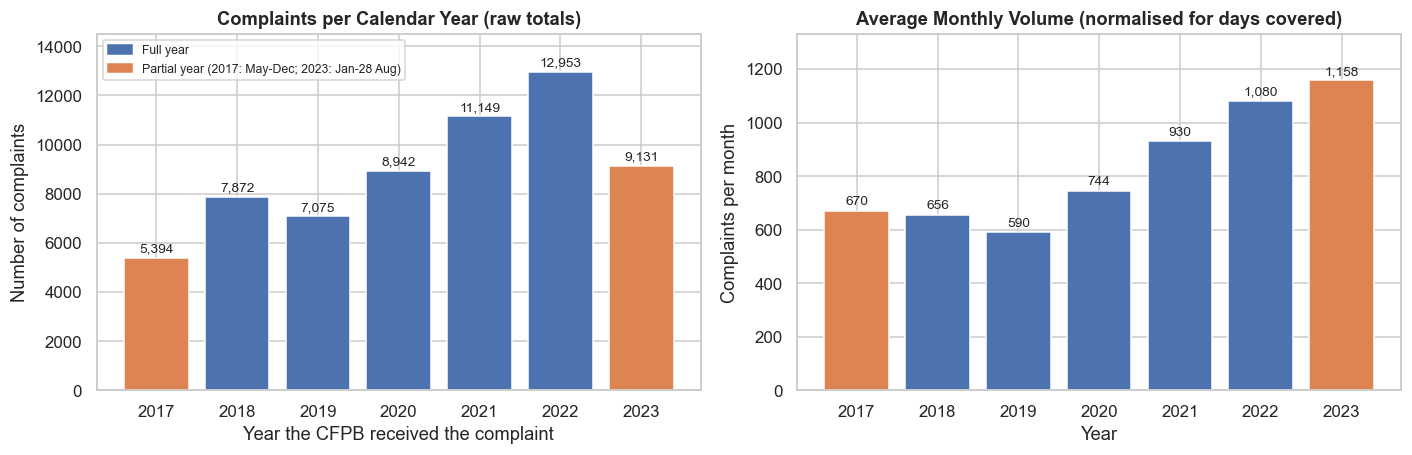

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
colors = [PAL[0] if c == "full year" else PAL[1] for c in annual["coverage"]]
b = axes[0].bar(annual.index.astype(str), annual["complaints"], color=colors)
axes[0].bar_label(b, labels=[f"{v:,}" for v in annual["complaints"]], padding=2, fontsize=9)
axes[0].set_title("Complaints per Calendar Year (raw totals)")
axes[0].set_xlabel("Year the CFPB received the complaint")
axes[0].set_ylabel("Number of complaints")
axes[0].set_ylim(0, annual["complaints"].max() * 1.12)
from matplotlib.patches import Patch
axes[0].legend(handles=[Patch(color=PAL[0], label="Full year"), Patch(color=PAL[1], label="Partial year (2017: May-Dec; 2023: Jan-28 Aug)")], loc="upper left", fontsize=8)
b2 = axes[1].bar(annual.index.astype(str), annual["avg_per_month_normalised"], color=colors)
axes[1].bar_label(b2, labels=[f"{v:,.0f}" for v in annual["avg_per_month_normalised"]], padding=2, fontsize=9)
axes[1].set_title("Average Monthly Volume (normalised for days covered)")
axes[1].set_xlabel("Year")
axes[1].set_ylabel("Complaints per month")
axes[1].set_ylim(0, annual["avg_per_month_normalised"].max() * 1.15)
save_fig("02_annual_volumes")

**Visualization 3 – Monthly complaint volume.** August 2023 is excluded from the monthly series because the data end on 28 August. The spike in July 2023 is investigated below.

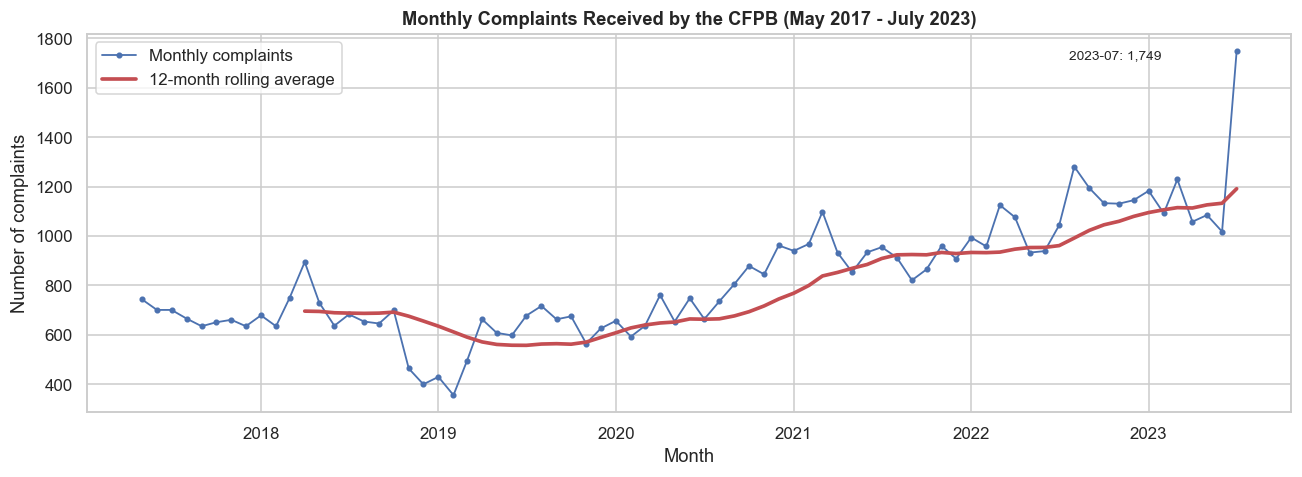

In [12]:
monthly_all = df.groupby("year_month").size()
monthly = monthly_all[monthly_all.index <= pd.Period("2023-07", "M")]      # complete months only
roll12 = monthly.rolling(12, center=False).mean()

fig, ax = plt.subplots(figsize=(12, 4.5))
x = monthly.index.to_timestamp()
ax.plot(x, monthly.values, marker="o", ms=3, lw=1.2, color=PAL[0], label="Monthly complaints")
ax.plot(x, roll12.values, lw=2.4, color=PAL[3], label="12-month rolling average")
peak = monthly.idxmax()
ax.annotate(f"{peak}: {monthly.max():,}", xy=(peak.to_timestamp(), monthly.max()), xytext=(-110, -5),
            textcoords="offset points", arrowprops={"arrowstyle": "->"}, fontsize=9)
ax.set_title("Monthly Complaints Received by the CFPB (May 2017 - July 2023)")
ax.set_xlabel("Month")
ax.set_ylabel("Number of complaints")
ax.legend()
save_fig("03_monthly_volume")

**Visualization 4 – Like-for-like comparison (January to June only).** Every year is compared over the same six months. July is left out because of the July 2023 spike, and August 2023 is incomplete.

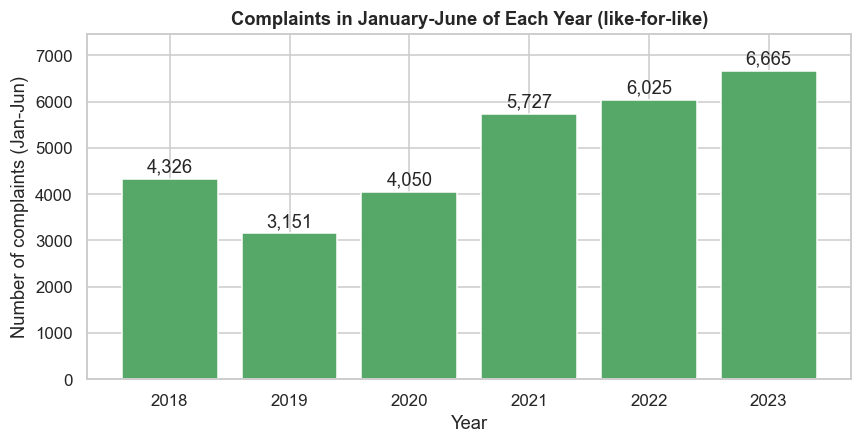

Growth in Jan-Jun volume: 2018 -> 2023: +54%;  2022 -> 2023: +11%


In [13]:
jan_jul = df[df["month"] <= 6].groupby("year").size()      # Jan-Jun like-for-like
jan_jul = jan_jul.loc[2018:2023]
fig, ax = plt.subplots(figsize=(8, 4.2))
bars = ax.bar(jan_jul.index.astype(str), jan_jul.values, color=PAL[2])
ax.bar_label(bars, labels=[f"{v:,}" for v in jan_jul.values], padding=2)
ax.set_title("Complaints in January-June of Each Year (like-for-like)")
ax.set_xlabel("Year")
ax.set_ylabel("Number of complaints (Jan-Jun)")
ax.set_ylim(0, jan_jul.max() * 1.12)
save_fig("04_jan_jun_comparison")
print("Growth in Jan-Jun volume:", f"2018 -> 2023: {jan_jul.loc[2023] / jan_jul.loc[2018] - 1:+.0%};  2022 -> 2023: {jan_jul.loc[2023] / jan_jul.loc[2022] - 1:+.0%}")

### 5.2 The July 2023 spike and day-of-week pattern

In [14]:
daily = df.groupby("date_received_by_cfpb").size()
print(f"Daily complaints: median = {daily.median():.0f}, mean = {daily.mean():.1f}, max = {daily.max()} on {daily.idxmax().date()}")
print()
print("Ten busiest days")
display(daily.sort_values(ascending=False).head(10).rename("complaints").to_frame())

spike_days = df[(df["date_received_by_cfpb"] >= "2023-07-11") & (df["date_received_by_cfpb"] <= "2023-07-18")]
print(f"11-18 July 2023: {len(spike_days):,} complaints ({len(spike_days) / monthly_all.loc[pd.Period('2023-07', 'M')]:.0%} of July)")
display(pd.DataFrame({"share_during_spike": spike_days["product_group"].value_counts(normalize=True).round(3),
                      "share_all_other_data": df.loc[~df.index.isin(spike_days.index), "product_group"].value_counts(normalize=True).round(3)}).loc[PRODUCT_ORDER])

Daily complaints: median = 27, mean = 27.1, max = 183 on 2023-07-12

Ten busiest days


,complaints
date_received_by_cfpb,
2023-07-12,183
2023-07-13,148
2023-07-11,108
2023-07-14,98
2023-07-15,81
2023-07-17,78
2023-04-27,74
2023-07-18,68
2018-04-05,66


11-18 July 2023: 804 complaints (46% of July)


,share_during_spike,share_all_other_data
product_group,,
Checking/savings account,0.541,0.395
Credit/prepaid card,0.285,0.259
Credit reporting,0.075,0.124
Mortgage,0.032,0.107
Money transfer/service,0.042,0.055
Debt collection,0.015,0.044
Other products,0.010,0.016


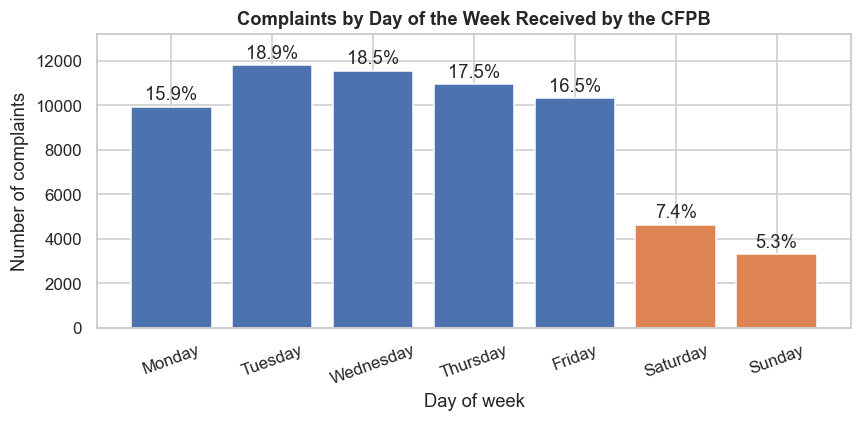

In [15]:
dow_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
dow = df["weekday"].value_counts().reindex(dow_order)
fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(dow.index, dow.values, color=[PAL[0]] * 5 + [PAL[1]] * 2)
ax.bar_label(bars, labels=[f"{v / len(df):.1%}" for v in dow.values], padding=2)
ax.set_title("Complaints by Day of the Week Received by the CFPB")
ax.set_xlabel("Day of week")
ax.set_ylabel("Number of complaints")
ax.set_ylim(0, dow.max() * 1.12)
plt.xticks(rotation=20)
save_fig("05_day_of_week")

**Reading the results.** The single busiest period is 11 to 18 July 2023, with 12 July alone at 183 complaints (typical days have about 27). The spike is dominated by checking/savings and credit/prepaid-card complaints. **The data cannot reveal why**: it could be a product event, a media or regulatory event, a data-batch effect, or a coincidence. It is kept in the data and handled with a sensitivity analysis in H1. About 87% of complaints are received on weekdays.

### 5.3 Products, issues and states (business questions 2, 3 and 4)

,complaints,share_pct
product_group,,
Checking/savings account,24814,39.7
Credit/prepaid card,16197,25.9
Credit reporting,7710,12.3
Mortgage,6601,10.6
Money transfer/service,3453,5.5
Debt collection,2736,4.4
Other products,1005,1.6


Original product labels in 'Other products':


,complaints
product,
Vehicle loan or lease,633
"Payday loan, title loan, or personal loan",333
Student loan,39


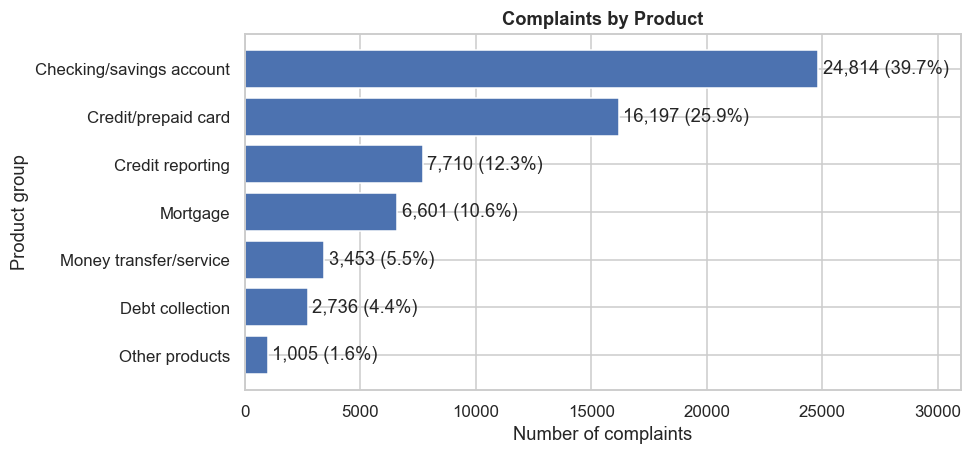

In [16]:
prod = df["product_group"].value_counts().reindex(PRODUCT_ORDER)
prod_tbl = pd.DataFrame({"complaints": prod, "share_pct": (prod / len(df) * 100).round(1)})
display(prod_tbl)
print("Original product labels in 'Other products':")
display(df.loc[df["product_group"] == "Other products", "product"].value_counts().to_frame("complaints"))

fig, ax = plt.subplots(figsize=(9, 4.3))
bars = ax.barh(prod.index[::-1], prod.values[::-1], color=PAL[0])
ax.bar_label(bars, labels=[f"{v:,} ({v / len(df):.1%})" for v in prod.values[::-1]], padding=3)
ax.set_title("Complaints by Product")
ax.set_xlabel("Number of complaints")
ax.set_ylabel("Product group")
ax.set_xlim(0, prod.max() * 1.25)
save_fig("06_complaints_by_product")

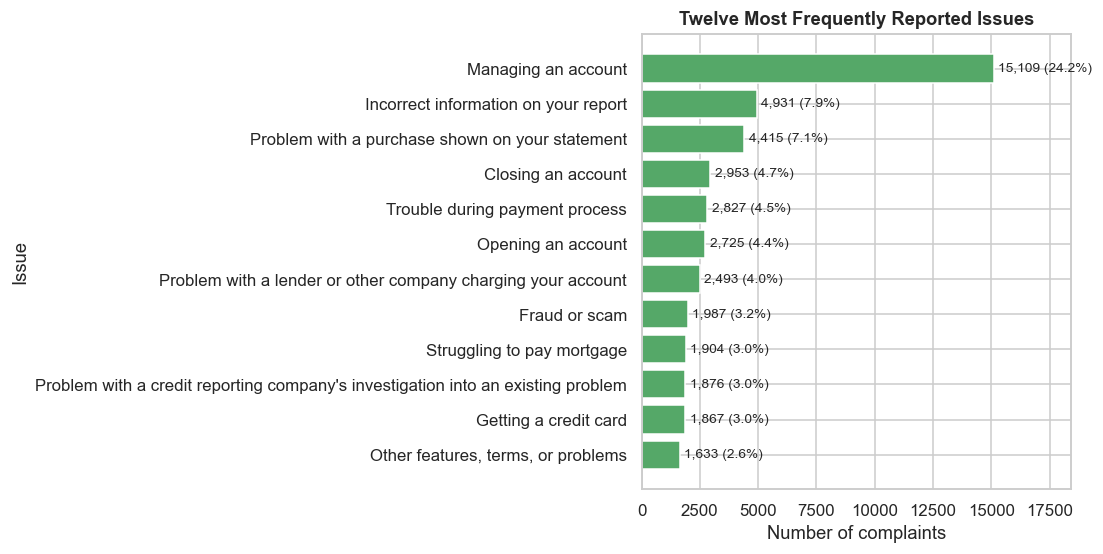

Distinct issues: 76;  the top 12 account for 71.5% of complaints


In [17]:
top_issues = df["issue"].value_counts().head(12)
fig, ax = plt.subplots(figsize=(10, 5.2))
bars = ax.barh(top_issues.index[::-1], top_issues.values[::-1], color=PAL[2])
ax.bar_label(bars, labels=[f"{v:,} ({v / len(df):.1%})" for v in top_issues.values[::-1]], padding=3, fontsize=9)
ax.set_title("Twelve Most Frequently Reported Issues")
ax.set_xlabel("Number of complaints")
ax.set_ylabel("Issue")
ax.set_xlim(0, top_issues.max() * 1.22)
save_fig("07_top_issues")
print(f"Distinct issues: {df['issue'].nunique()};  the top 12 account for {top_issues.sum() / len(df):.1%} of complaints")

**Visualization 8 – How issues differ by product.** Each column shows the share of *that product's* complaints reporting each issue (rows are every product's top-2 issues). Issues are largely product-specific, so any comparison of issues is also a comparison of products.

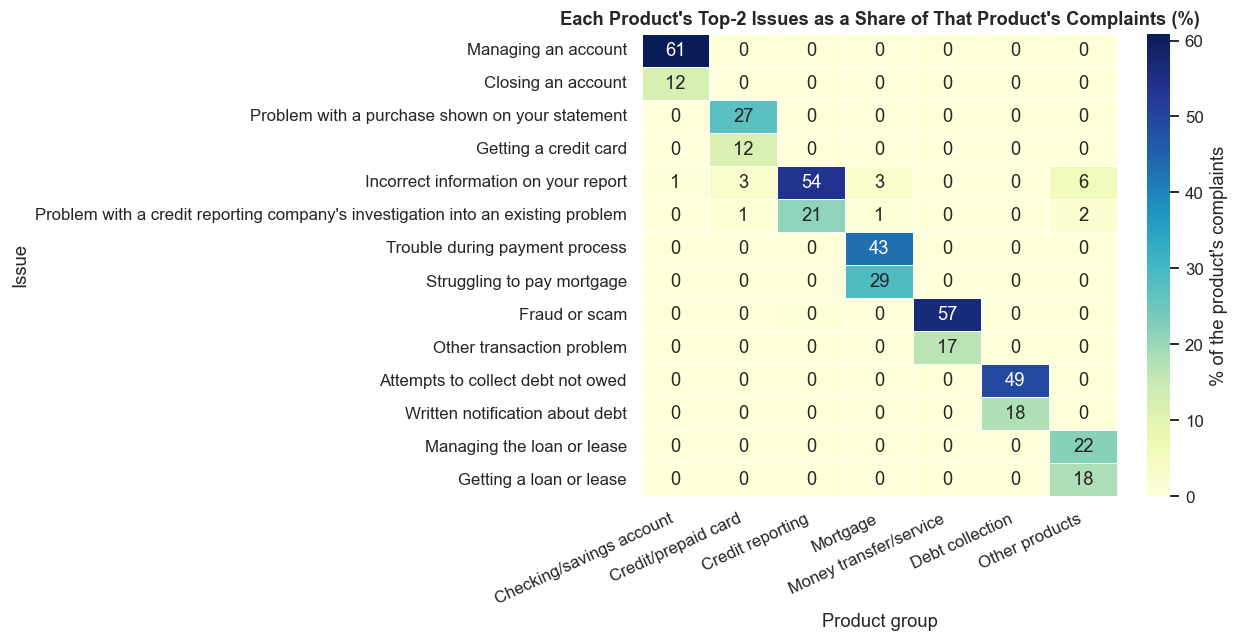

Most common issue within each product


,most common issue (share of product)
product_group,
Checking/savings account,Managing an account (61%)
Credit/prepaid card,Problem with a purchase shown on your statemen...
Credit reporting,Incorrect information on your report (54%)
Mortgage,Trouble during payment process (43%)
Money transfer/service,Fraud or scam (57%)
Debt collection,Attempts to collect debt not owed (49%)
Other products,Managing the loan or lease (22%)


In [18]:
issue_set = []
for p in PRODUCT_ORDER:
    issue_set += df.loc[df["product_group"] == p, "issue"].value_counts().head(2).index.tolist()
issue_set = list(dict.fromkeys(issue_set))     # unique, order preserved
ct_i = pd.crosstab(df["issue"], df["product_group"]).reindex(columns=PRODUCT_ORDER, fill_value=0).loc[issue_set]
share = ct_i / df["product_group"].value_counts().reindex(PRODUCT_ORDER) * 100
fig, ax = plt.subplots(figsize=(11.5, 6))
sns.heatmap(share, annot=True, fmt=".0f", cmap="YlGnBu", linewidths=0.4, ax=ax, cbar_kws={"label": "% of the product's complaints"})
ax.set_title("Each Product's Top-2 Issues as a Share of That Product's Complaints (%)")
ax.set_xlabel("Product group")
ax.set_ylabel("Issue")
plt.xticks(rotation=25, ha="right")
save_fig("08_issue_by_product_heatmap")

print("Most common issue within each product")
top_by_prod = df.groupby("product_group")["issue"].agg(lambda s: f"{s.value_counts().index[0]} ({s.value_counts(normalize=True).iloc[0]:.0%})")
display(top_by_prod.reindex(PRODUCT_ORDER).rename("most common issue (share of product)").to_frame())

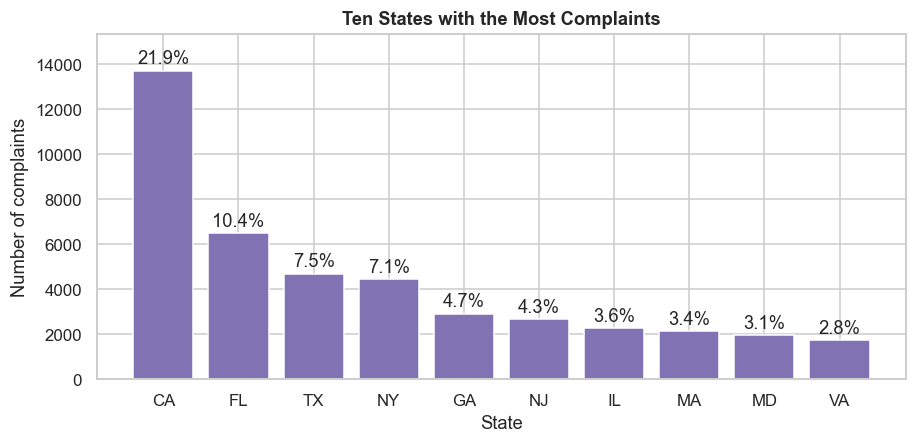

The top 5 states account for 51.6% of complaints. No population or customer-base data are available, so these are raw counts, not rates.


In [19]:
state = df["state"].value_counts()
top_states = state.head(10)
fig, ax = plt.subplots(figsize=(8.5, 4.2))
bars = ax.bar(top_states.index, top_states.values, color=PAL[4])
ax.bar_label(bars, labels=[f"{v / len(df):.1%}" for v in top_states.values], padding=2)
ax.set_title("Ten States with the Most Complaints")
ax.set_xlabel("State")
ax.set_ylabel("Number of complaints")
ax.set_ylim(0, top_states.max() * 1.12)
save_fig("09_top_states")
print(f"The top 5 states account for {state.head(5).sum() / len(df):.1%} of complaints. No population or customer-base data are available, so these are raw counts, not rates.")

### 5.4 Submission channels

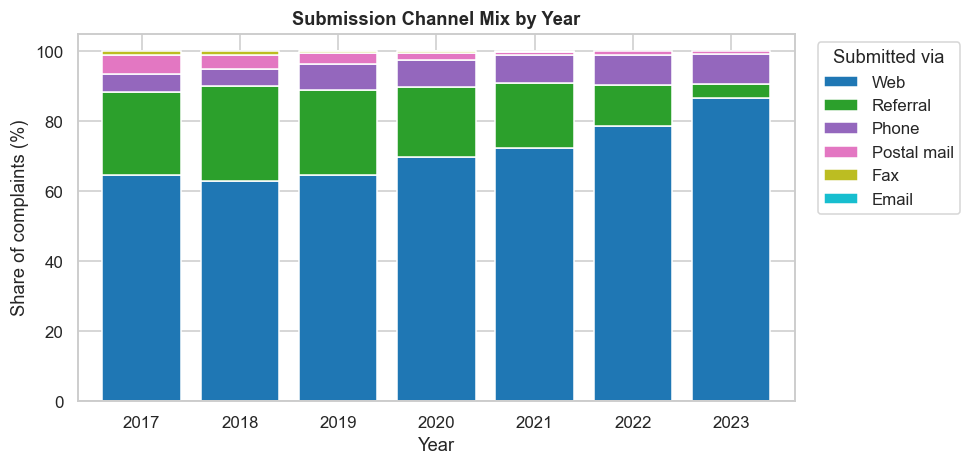

,complaints,share_pct
submitted_via,,
Web,45423,72.66
Referral,10856,17.37
Phone,4684,7.49
Postal mail,1318,2.11
Fax,233,0.37
Email,2,0.00


In [20]:
via_year = pd.crosstab(df["year"], df["submitted_via"], normalize="index") * 100
via_year = via_year[["Web", "Referral", "Phone", "Postal mail", "Fax", "Email"]]
fig, ax = plt.subplots(figsize=(9, 4.4))
via_year.plot(kind="bar", stacked=True, ax=ax, colormap="tab10", width=0.8)
ax.set_title("Submission Channel Mix by Year")
ax.set_xlabel("Year")
ax.set_ylabel("Share of complaints (%)")
ax.legend(title="Submitted via", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.xticks(rotation=0)
save_fig("10_channel_mix_by_year")
display(df["submitted_via"].value_counts().to_frame("complaints").assign(share_pct=lambda t: (t["complaints"] / len(df) * 100).round(2)))

### 5.5 Company responses and timeliness (business questions 6 and 7)

Because the brief warns against confusing blanks with "No", timeliness percentages are reported two ways: **of all complaints**, and **of complaints where timeliness has been determined** (excluding *In progress*).

In [21]:
resp = df["company_response"].value_counts()
resp_tbl = pd.DataFrame({"complaints": resp, "share_pct": (resp / len(df) * 100).round(2)})
print("COMPANY RESPONSE TO CONSUMER")
display(resp_tbl)
print("COMPANY PUBLIC RESPONSE")
pub = df["public_response"].value_counts()
display(pd.DataFrame({"complaints": pub, "share_pct": (pub / len(df) * 100).round(2)}))

n_yes = (df["timely_status"] == "Timely").sum(); n_no = (df["timely_status"] == "Not timely").sum(); n_nd = (df["timely_status"] == "Not yet determined").sum()
print()
print(f"TIMELINESS: Timely = {n_yes:,};  Not timely = {n_no:,};  Not yet determined (In progress) = {n_nd:,}")
print(f"  % timely of ALL complaints                   : {n_yes / len(df):.2%}")
print(f"  % timely of DETERMINED complaints (Yes+No)   : {n_yes / (n_yes + n_no):.2%}")
lo, hi = wilson_ci(n_yes, n_yes + n_no)
print(f"  95% Wilson CI for the determined share       : {lo:.2%} to {hi:.2%}")
print(f"  In-progress complaints by year               : {df.groupby('year')['is_in_progress'].sum().to_dict()}")

COMPANY RESPONSE TO CONSUMER


,complaints,share_pct
company_response,,
Closed with explanation,41044,65.65
Closed with monetary relief,14697,23.51
Closed with non-monetary relief,5273,8.43
In progress,1494,2.39
Closed (no detail),8,0.01


COMPANY PUBLIC RESPONSE


,complaints,share_pct
public_response,,
Responded; no public response provided,60311,96.47
Not recorded,2175,3.48
Believes complaint gave opportunity to answer questions,12,0.02
Believes result of a misunderstanding,7,0.01
Believes it acted appropriately,6,0.01
Attributes to third party,3,0.00
Disputes the facts,2,0.00



TIMELINESS: Timely = 58,619;  Not timely = 2,403;  Not yet determined (In progress) = 1,494
  % timely of ALL complaints                   : 93.77%
  % timely of DETERMINED complaints (Yes+No)   : 96.06%
  95% Wilson CI for the determined share       : 95.90% to 96.21%
  In-progress complaints by year               : {2017: 0, 2018: 0, 2019: 0, 2020: 0, 2021: 0, 2022: 0, 2023: 1494}


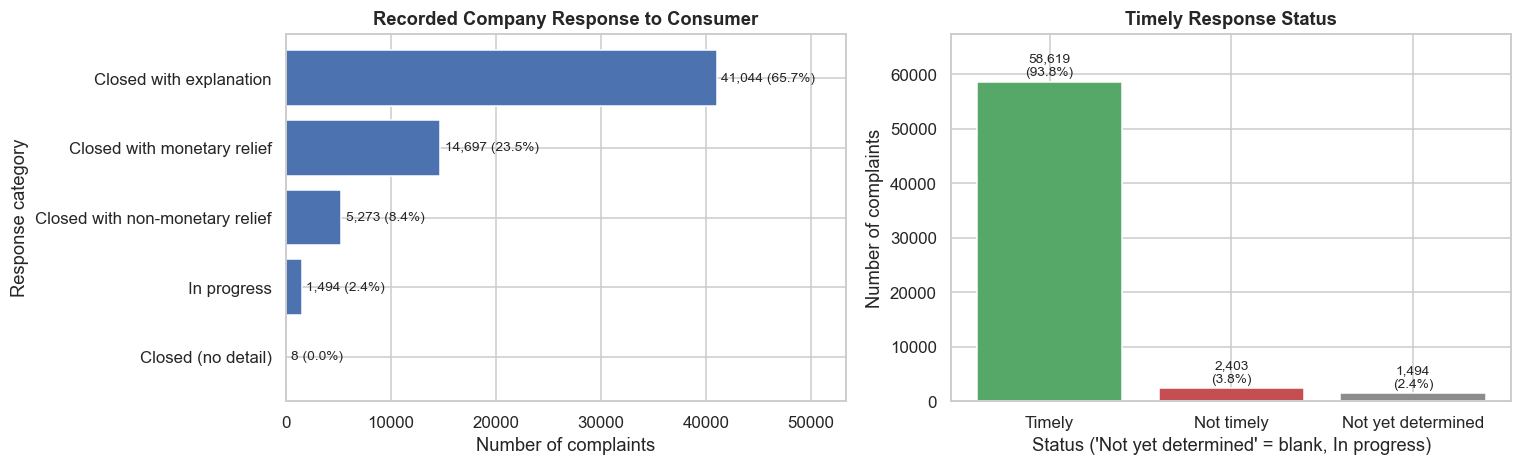

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
order = ["Closed with explanation", "Closed with monetary relief", "Closed with non-monetary relief", "In progress", "Closed (no detail)"]
r = df["company_response"].value_counts().reindex(order)
bars = axes[0].barh(r.index[::-1], r.values[::-1], color=PAL[0])
axes[0].bar_label(bars, labels=[f"{v:,} ({v / len(df):.1%})" for v in r.values[::-1]], padding=3, fontsize=9)
axes[0].set_title("Recorded Company Response to Consumer")
axes[0].set_xlabel("Number of complaints")
axes[0].set_ylabel("Response category")
axes[0].set_xlim(0, r.max() * 1.3)

ts = df["timely_status"].value_counts().reindex(["Timely", "Not timely", "Not yet determined"])
bars = axes[1].bar(ts.index, ts.values, color=[PAL[2], PAL[3], PAL[7]])
axes[1].bar_label(bars, labels=[f"{v:,}\n({v / len(df):.1%})" for v in ts.values], padding=2, fontsize=9)
axes[1].set_title("Timely Response Status")
axes[1].set_xlabel("Status ('Not yet determined' = blank, In progress)")
axes[1].set_ylabel("Number of complaints")
axes[1].set_ylim(0, ts.max() * 1.15)
save_fig("11_response_and_timeliness")

**Visualization 12 – Share of 'not timely' responses by month.** Months are shown only where timeliness has been determined. The share is near zero until 2020, then jumps in mid-2021.

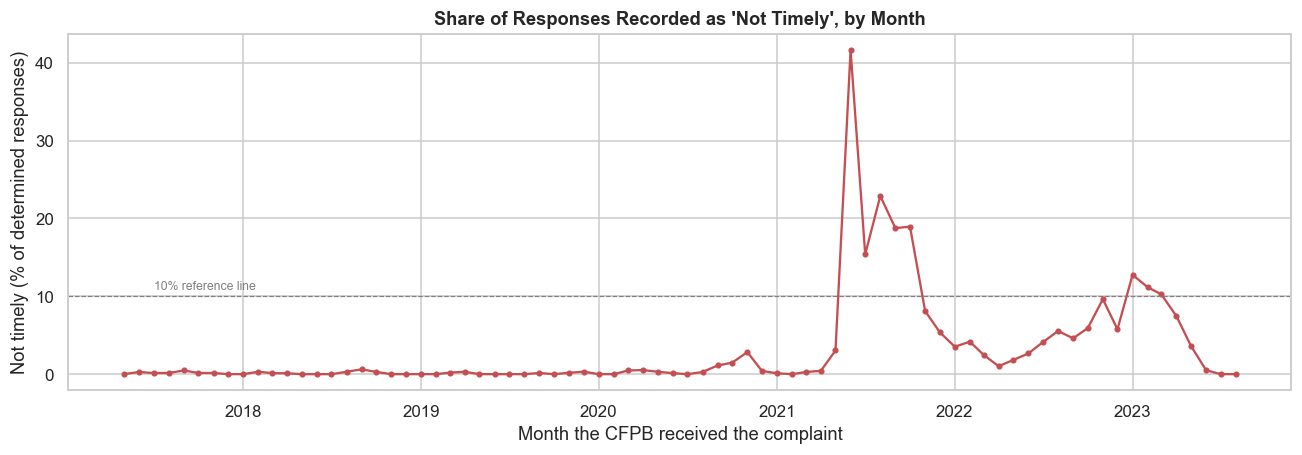

Months with more than 10% not timely: ['2021-06', '2021-07', '2021-08', '2021-09', '2021-10', '2023-01', '2023-02', '2023-03']


In [23]:
det = df[df["timely_status"] != "Not yet determined"]
nt_month = det.groupby("year_month")["timely_status"].apply(lambda s: (s == "Not timely").mean() * 100)
nt_month = nt_month[nt_month.index <= pd.Period("2023-08", "M")]
fig, ax = plt.subplots(figsize=(12, 4.3))
ax.plot(nt_month.index.to_timestamp(), nt_month.values, color=PAL[3], marker="o", ms=3)
ax.axhline(10, color="grey", ls="--", lw=0.8)
ax.text(nt_month.index.to_timestamp()[2], 10.8, "10% reference line", fontsize=8, color="grey")
ax.set_title("Share of Responses Recorded as 'Not Timely', by Month")
ax.set_xlabel("Month the CFPB received the complaint")
ax.set_ylabel("Not timely (% of determined responses)")
save_fig("12_not_timely_by_month")
print("Months with more than 10% not timely:", [str(m) for m in nt_month[nt_month > 10].index])

### 5.6 CFPB forwarding intervals (business question 5)

In [24]:
fd = df["forwarding_days"]
qs = fd.quantile([0.5, 0.75, 0.9, 0.95, 0.99])
print("FORWARDING INTERVAL (days from CFPB receipt to CFPB sending the complaint to the company)")
print(f"  Mean {fd.mean():.2f},  median {fd.median():.0f},  std {fd.std():.2f},  max {fd.max()}")
print(f"  75th pct {qs[0.75]:.0f},  90th pct {qs[0.9]:.0f},  95th pct {qs[0.95]:.0f},  99th pct {qs[0.99]:.0f}")
for k in [0, 1, 3, 7, 14, 30]:
    print(f"  Forwarded within {k:2d} day(s): {(fd <= k).mean():.1%}")
print(f"  Longer than 30 days: {(fd > 30).sum():,} complaints ({(fd > 30).mean():.2%})")
print("  The distribution is extremely skewed, so medians and percentiles are used instead of means.")

FORWARDING INTERVAL (days from CFPB receipt to CFPB sending the complaint to the company)
  Mean 1.22,  median 0,  std 5.65,  max 275
  75th pct 0,  90th pct 2,  95th pct 5,  99th pct 25
  Forwarded within  0 day(s): 79.4%
  Forwarded within  1 day(s): 88.3%
  Forwarded within  3 day(s): 92.9%
  Forwarded within  7 day(s): 96.1%
  Forwarded within 14 day(s): 97.6%
  Forwarded within 30 day(s): 99.3%
  Longer than 30 days: 435 complaints (0.70%)
  The distribution is extremely skewed, so medians and percentiles are used instead of means.


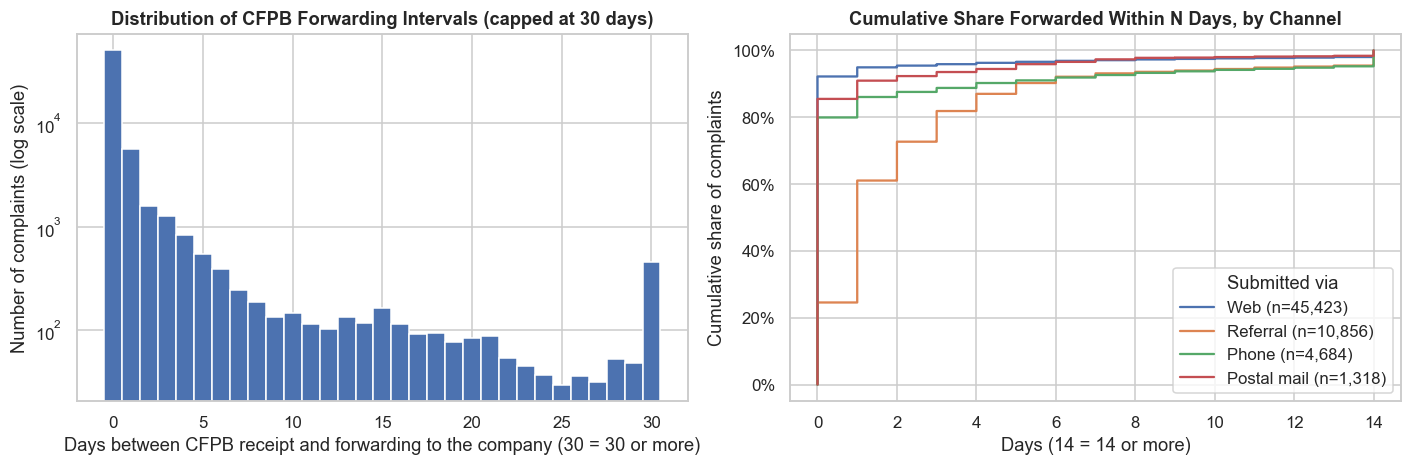

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
axes[0].hist(fd.clip(upper=30), bins=np.arange(-0.5, 31.5, 1), color=PAL[0], edgecolor="white")
axes[0].set_yscale("log")
axes[0].set_title("Distribution of CFPB Forwarding Intervals (capped at 30 days)")
axes[0].set_xlabel("Days between CFPB receipt and forwarding to the company (30 = 30 or more)")
axes[0].set_ylabel("Number of complaints (log scale)")
for ch, col in zip(["Web", "Referral", "Phone", "Postal mail"], PAL):
    s = np.sort(df.loc[df["submitted_via"] == ch, "forwarding_days"].clip(upper=14).values)
    axes[1].plot(s, np.arange(1, len(s) + 1) / len(s), label=f"{ch} (n={len(s):,})", color=col, drawstyle="steps-post")
axes[1].set_title("Cumulative Share Forwarded Within N Days, by Channel")
axes[1].set_xlabel("Days (14 = 14 or more)")
axes[1].set_ylabel("Cumulative share of complaints")
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
axes[1].legend(title="Submitted via")
save_fig("13_forwarding_interval")

## 6. Statistical Analysis

For every hypothesis the notebook (1) states the test, (2) checks its assumptions, (3) reports the statistic, p-value **and effect size**, and (4) interprets the result. Chi-square tests require expected cell counts of at least 5 in at least about 80% of cells; rank-based tests are used where distributions are heavily skewed.

### 6.1 H1: Did complaint volumes differ across the reporting years?

In [26]:
y = monthly.values.astype(float); t = np.arange(len(y))
print(f"Complete months analysed: {len(y)} (May 2017 - July 2023)")

# Assumption checks
sh = stats.shapiro(y)
lag1 = pd.Series(y).autocorr(1)
print(f"Shapiro-Wilk normality of monthly counts: W = {sh.statistic:.3f}, {fmt_p(sh.pvalue)}  -> non-normal, so rank-based tests are used")
print(f"Lag-1 autocorrelation of the monthly series: {lag1:.2f}  -> consecutive months are NOT independent, so p-values are optimistic;")
print("   a moving-block bootstrap confidence interval for the trend is therefore also reported.")

# (a) Monotonic trend: Kendall's tau (Mann-Kendall equivalent) + Theil-Sen slope
tau, p_tau = stats.kendalltau(t, y)
ts_slope, ts_int, ts_lo, ts_hi = stats.theilslopes(y, t, 0.95)
bb_slope, bb_ci = block_bootstrap_slope(y)
print()
print("(a) TREND over all 75 months")
print(f"    Kendall tau = {tau:.2f}, {fmt_p(p_tau)}")
rho, p_rho = stats.spearmanr(t, y)
print(f"    Spearman rho = {rho:.2f}, {fmt_p(p_rho)}  (also reported because the earlier draft used it; Kendall's tau is the primary test)")
print(f"    Theil-Sen slope = {ts_slope:+.1f} complaints per month (95% CI {ts_lo:+.1f} to {ts_hi:+.1f})")
print(f"    Block-bootstrap 95% CI for the slope: {bb_ci[0]:+.1f} to {bb_ci[1]:+.1f}")
print(f"    That is roughly {ts_slope * 12:+.0f} more complaints per month for each year that passes")

# Sensitivity: drop the July 2023 spike
y2 = y[:-1]; t2 = t[:-1]
tau2, p_tau2 = stats.kendalltau(t2, y2); slope2 = stats.theilslopes(y2, t2)[0]
print(f"    Sensitivity (July 2023 excluded): tau = {tau2:.2f}, {fmt_p(p_tau2)}, slope = {slope2:+.1f} per month")
log_result("H1", "Kendall tau trend, 75 monthly counts", f"tau = {tau:.2f}", p_tau, f"Theil-Sen slope {ts_slope:+.1f}/month (block-bootstrap 95% CI {bb_ci[0]:+.1f} to {bb_ci[1]:+.1f})", "Reject H0: upward trend")

Complete months analysed: 75 (May 2017 - July 2023)
Shapiro-Wilk normality of monthly counts: W = 0.943, p = 0.002  -> non-normal, so rank-based tests are used
Lag-1 autocorrelation of the monthly series: 0.86  -> consecutive months are NOT independent, so p-values are optimistic;
   a moving-block bootstrap confidence interval for the trend is therefore also reported.

(a) TREND over all 75 months
    Kendall tau = 0.59, p < 0.001
    Spearman rho = 0.80, p < 0.001  (also reported because the earlier draft used it; Kendall's tau is the primary test)
    Theil-Sen slope = +8.2 complaints per month (95% CI +6.7 to +10.0)
    Block-bootstrap 95% CI for the slope: +5.6 to +10.7
    That is roughly +99 more complaints per month for each year that passes
    Sensitivity (July 2023 excluded): tau = 0.58, p < 0.001, slope = +7.9 per month


In [27]:
# (b) Differences between FULL calendar years 2018-2022 (monthly counts)
yrs = list(range(2018, 2023))
groups = [monthly[monthly.index.year == yr].values for yr in yrs]
H, p_kw = stats.kruskal(*groups)
n_tot = sum(len(g) for g in groups)
eps2 = epsilon_squared(H, n_tot)
print("(b) KRUSKAL-WALLIS across full years 2018-2022 (60 monthly counts)")
print(f"    H = {H:.2f}, df = {len(yrs) - 1}, {fmt_p(p_kw)}, epsilon-squared = {eps2:.2f} (large effect if > 0.14)")
log_result("H1", "Kruskal-Wallis, monthly counts 2018-2022", f"H = {H:.1f}", p_kw, f"epsilon-squared = {eps2:.2f} ({eps_label(eps2)})", "Reject H0: years differ")

summary_year = pd.DataFrame({"months": [len(g) for g in groups], "mean": [g.mean() for g in groups],
                             "median": [np.median(g) for g in groups], "min": [g.min() for g in groups],
                             "max": [g.max() for g in groups]}, index=yrs).round(0).astype(int)
display(summary_year)

pairs = list(itertools.combinations(range(len(yrs)), 2))
raw_p = []; eff = []
for i, j in pairs:
    c, p = cles(groups[j], groups[i]); raw_p.append(p); eff.append(c)
adj = holm_adjust(raw_p)
posthoc = pd.DataFrame({"comparison": [f"{yrs[j]} vs {yrs[i]}" for i, j in pairs],
                        "P(later year > earlier year)": np.round(eff, 2), "p_raw": raw_p, "p_Holm": adj,
                        "significant (Holm < 0.05)": adj < 0.05})
print("Pairwise Mann-Whitney tests (Holm-adjusted); 0.5 = no difference, 1.0 = every later month higher")
display(posthoc.style.format({"P(later year > earlier year)": "{:.2f}", "p_raw": "{:.4f}", "p_Holm": "{:.4f}"}))

(b) KRUSKAL-WALLIS across full years 2018-2022 (60 monthly counts)
    H = 44.40, df = 4, p < 0.001, epsilon-squared = 0.75 (large effect if > 0.14)


,months,mean,median,min,max
2018,12,656,666,400,895
2019,12,590,617,356,717
2020,12,745,742,593,962
2021,12,929,934,821,1098
2022,12,1079,1100,933,1281


Pairwise Mann-Whitney tests (Holm-adjusted); 0.5 = no difference, 1.0 = every later month higher


,comparison,P(later year > earlier year),p_raw,p_Holm,significant (Holm < 0.05)
0,2019 vs 2018,0.31,0.1123,0.2245,False
1,2020 vs 2018,0.69,0.1259,0.2245,False
2,2021 vs 2018,0.98,0.0001,0.0005,True
3,2022 vs 2018,1.00,0.0000,0.0004,True
4,2020 vs 2019,0.82,0.0086,0.0258,True
5,2021 vs 2019,1.00,0.0000,0.0004,True
6,2022 vs 2019,1.00,0.0000,0.0004,True
7,2021 vs 2020,0.90,0.0009,0.0045,True
8,2022 vs 2020,0.98,0.0001,0.0005,True
9,2022 vs 2021,0.88,0.0018,0.0073,True


In [28]:
# (c) Seasonality check: is any calendar month systematically busier? (detrended by dividing by each year's mean)
ratios = []
for yr in yrs:
    s = monthly[monthly.index.year == yr]
    ratios.append(pd.DataFrame({"month": s.index.month, "ratio": s.values / s.mean()}))
ratios = pd.concat(ratios)
H_s, p_s = stats.kruskal(*[ratios.loc[ratios["month"] == m, "ratio"].values for m in range(1, 13)])
print(f"(c) SEASONALITY (12 calendar months, 2018-2022): Kruskal-Wallis H = {H_s:.1f}, {fmt_p(p_s)}")
log_result("H1", "Kruskal-Wallis, seasonality (calendar month)", f"H = {H_s:.1f}", p_s, "detrended ratios", "Seasonality not significant" if p_s >= 0.05 else "Seasonality present")

(c) SEASONALITY (12 calendar months, 2018-2022): Kruskal-Wallis H = 12.4, p = 0.336


**Visualization 14 – Monthly volume by year, and seasonality.**

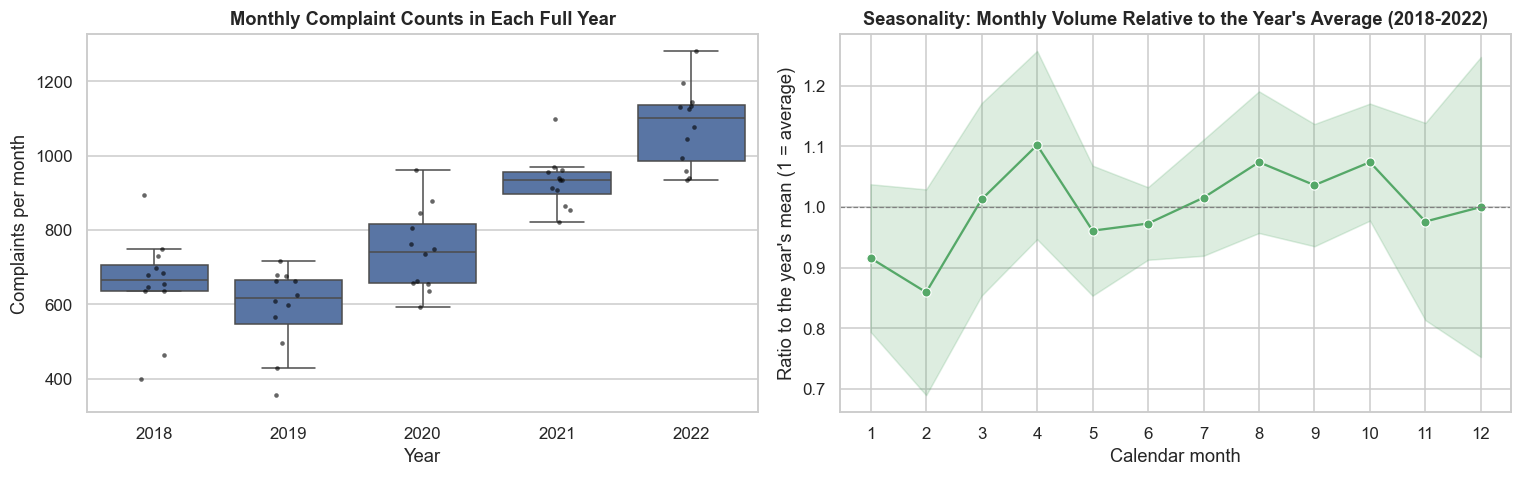

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
plot_df = monthly[(monthly.index.year >= 2018) & (monthly.index.year <= 2022)].rename("complaints").reset_index()
plot_df["year"] = plot_df["year_month"].dt.year
sns.boxplot(data=plot_df, x="year", y="complaints", ax=axes[0], color=PAL[0], showfliers=False)
sns.stripplot(data=plot_df, x="year", y="complaints", ax=axes[0], color="black", size=3, alpha=0.6)
axes[0].set_title("Monthly Complaint Counts in Each Full Year")
axes[0].set_xlabel("Year")
axes[0].set_ylabel("Complaints per month")

sns.lineplot(data=ratios, x="month", y="ratio", errorbar="sd", marker="o", ax=axes[1], color=PAL[2])
axes[1].axhline(1, color="grey", ls="--", lw=0.8)
axes[1].set_title("Seasonality: Monthly Volume Relative to the Year's Average (2018-2022)")
axes[1].set_xlabel("Calendar month")
axes[1].set_ylabel("Ratio to the year's mean (1 = average)")
axes[1].set_xticks(range(1, 13))
save_fig("14_h1_year_and_seasonality")

**Interpretation (H1): reject H0. Complaint volumes rose over the period, and the years differ.**

- **Trend:** Kendall's tau = 0.59 (Spearman's rho = 0.80) across 75 complete months. The Theil-Sen slope is about **+8 complaints per month, every month** (roughly +99 per year). The block-bootstrap 95% interval (+5.6 to +10.7) excludes zero, so the upward trend survives the autocorrelation correction (lag-1 autocorrelation is 0.86, which makes the plain p-values optimistic). Removing July 2023 barely changes the result (tau = 0.58, slope +7.9).
- **Years differ:** Kruskal-Wallis H = 44.4, p < 0.001, epsilon-squared = 0.75 (a **large** effect). Average monthly volume was 656 (2018), 590 (2019), 745 (2020), 929 (2021) and 1,079 (2022). After Holm correction, 2018 vs 2019 and 2018 vs 2020 are **not** significantly different, while 2021 and 2022 are higher than every earlier year and 2022 is higher than 2021.
- **The path is not a straight line:** volumes dipped to a trough in early 2019 (the lowest month had 356 complaints) before rising from 2020.
- **Like-for-like check (January-June):** 4,326 complaints in 2018 versus 6,665 in 2023 (+54%), and +11% versus 2022. The raw 2023 total (9,131) is not comparable with full years because it covers only about eight months.
- **Seasonality:** no significant calendar-month pattern (p = 0.336). With only five full years this is weak evidence that seasonality is absent, not proof.

**Financial-services context.** Rising counts can reflect a larger customer base, easier filing (the web share of submissions rose from about 65% in 2017 to 87% in 2023), greater awareness of the complaint process, or genuine service problems. Without customer or account counts, the data cannot separate these explanations, so a rise in complaints is **not** evidence of worsening conduct.

### 6.2 H2: Has the product mix of complaints changed over time?

Chi-square test of independence between product group and year. All seven years are used because the test compares *shares*, which are not distorted by partial-year coverage.

In [30]:
ct2 = pd.crosstab(df["product_group"], df["year"]).loc[PRODUCT_ORDER]
display(ct2)
r2 = chi2_test(ct2)
print(f"Assumption check: minimum expected count = {r2['min_expected']:.1f}; cells with expected < 5: {r2['pct_cells_expected_lt5']:.0f}%  -> assumption met")
print(f"Chi-square = {r2['chi2']:,.1f}, df = {r2['dof']}, {fmt_p(r2['p'])}, n = {r2['n']:,}, {v_text(r2)}")
log_result("H2", "Chi-square: product group x year", f"chi2 = {r2['chi2']:,.0f}, df = {r2['dof']}", r2["p"], v_text(r2), "Reject H0: product mix changed (small effect)")

adj2 = adjusted_residuals(ct2, r2["expected"])

# Monthly mortgage share trend (complete months)
mort = df[df["product_group"] == "Mortgage"].groupby("year_month").size().reindex(monthly.index, fill_value=0)
mort_share = (mort / monthly * 100)
tau_m, p_m = stats.kendalltau(np.arange(len(mort_share)), mort_share.values)
share_by_year = (pd.crosstab(df["year"], df["product_group"], normalize="index") * 100).round(1)[PRODUCT_ORDER]
print(f"Mortgage share of monthly complaints: Kendall tau = {tau_m:.2f}, {fmt_p(p_m)}")
display(share_by_year)

year,2017,2018,2019,2020,2021,2022,2023
product_group,,,,,,,
Checking/savings account,2039,3176,3080,3242,4006,5186,4085
Credit/prepaid card,1125,1804,1789,2552,3084,3445,2398
Credit reporting,466,761,627,1044,1642,1858,1312
Mortgage,1248,1294,830,1143,953,774,359
Money transfer/service,141,306,333,432,599,1035,607
Debt collection,287,415,305,353,671,462,243
Other products,88,116,111,176,194,193,127


Assumption check: minimum expected count = 86.7; cells with expected < 5: 0%  -> assumption met
Chi-square = 2,871.2, df = 36, p < 0.001, n = 62,516, Cramer's V = 0.087 (small effect)
Mortgage share of monthly complaints: Kendall tau = -0.79, p < 0.001


product_group,Checking/savings account,Credit/prepaid card,Credit reporting,Mortgage,Money transfer/service,Debt collection,Other products
year,,,,,,,
2017,37.8,20.9,8.6,23.1,2.6,5.3,1.6
2018,40.3,22.9,9.7,16.4,3.9,5.3,1.5
2019,43.5,25.3,8.9,11.7,4.7,4.3,1.6
2020,36.3,28.5,11.7,12.8,4.8,3.9,2.0
2021,35.9,27.7,14.7,8.5,5.4,6.0,1.7
2022,40.0,26.6,14.3,6.0,8.0,3.6,1.5
2023,44.7,26.3,14.4,3.9,6.6,2.7,1.4


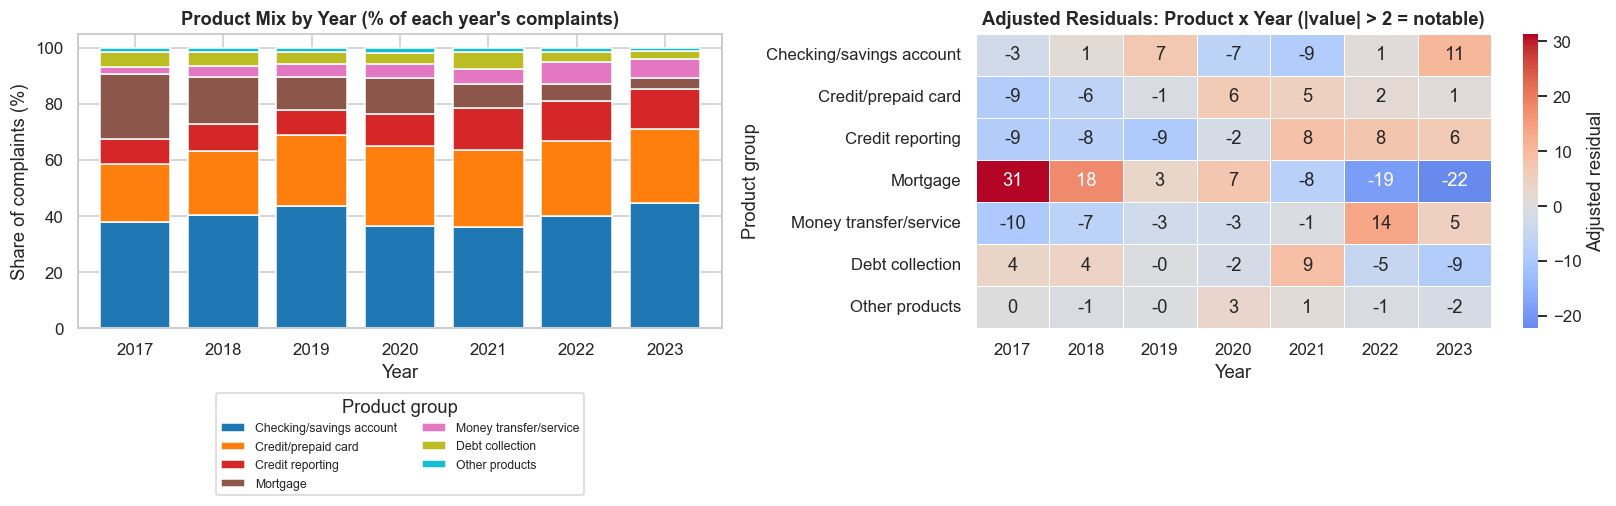

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
share_plot = pd.crosstab(df["year"], df["product_group"], normalize="index")[PRODUCT_ORDER] * 100
share_plot.plot(kind="bar", stacked=True, ax=axes[0], colormap="tab10", width=0.8)
axes[0].set_title("Product Mix by Year (% of each year's complaints)")
axes[0].set_xlabel("Year")
axes[0].set_ylabel("Share of complaints (%)")
axes[0].legend(title="Product group", fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2)
axes[0].tick_params(axis="x", rotation=0)
sns.heatmap(adj2, annot=True, fmt=".0f", cmap="coolwarm", center=0, linewidths=0.4, ax=axes[1], cbar_kws={"label": "Adjusted residual"})
axes[1].set_title("Adjusted Residuals: Product x Year (|value| > 2 = notable)")
axes[1].set_xlabel("Year")
axes[1].set_ylabel("Product group")
save_fig("15_h2_product_mix")

**Interpretation (H2): reject H0. The product mix changed, with a small overall effect but a very clear mortgage decline.**

- Chi-square = 2,871 (df = 36), p < 0.001, Cramer's V = 0.087 (small by the 7 x 7 table cut-offs). All expected counts exceed 5, so the assumption holds.
- **Mortgage** went from **23.1%** of complaints in 2017 to **3.9%** in 2023. This is not only a share effect: mortgage complaint counts fell from 1,294 (2018) to 774 (2022) while total volume rose. The monthly mortgage share has a strong downward trend (Kendall tau = -0.79). The adjusted residuals confirm it (+31 in 2017, -22 in 2023).
- **Credit reporting** rose from 8.6% to 14.4% and **checking/savings** from 37.8% (2017) to 44.7% (2023), with a dip to about 36% in 2020-2021. Because shares add to 100%, part of these increases is mechanical, a consequence of mortgage shrinking.

**Alternative explanations.** A change in the bank's mortgage business or servicing, a change in how complaints are classified into products, or a change in consumer behaviour could each produce this pattern. The data cannot tell them apart.

### 6.3 H3: Do CFPB forwarding intervals vary across products, channels and years?

Forwarding intervals are zero-inflated and heavily right-skewed (79% are same-day), so the **Kruskal-Wallis** test is used instead of ANOVA. Because product and channel are related, a **stratified check** tests whether product differences survive within a single channel.

In [32]:
# (a) By product
g_prod = [df.loc[df["product_group"] == p, "forwarding_days"].values for p in PRODUCT_ORDER]
H3a, p3a = stats.kruskal(*g_prod); e3a = epsilon_squared(H3a, len(df))
tbl3 = df.groupby("product_group")["forwarding_days"].agg(n="count", mean="mean", median="median",
        p90=lambda s: s.quantile(0.9), same_day=lambda s: (s == 0).mean() * 100).loc[PRODUCT_ORDER].round(2)
print("(a) BY PRODUCT")
display(tbl3)
print(f"    Kruskal-Wallis H = {H3a:.1f}, df = {len(PRODUCT_ORDER) - 1}, {fmt_p(p3a)}, epsilon-squared = {e3a:.4f} ({eps_label(e3a)})")
log_result("H3a", "Kruskal-Wallis: forwarding days by product", f"H = {H3a:.0f}", p3a, f"epsilon-squared = {e3a:.4f} ({eps_label(e3a)})", f"Significant, but {eps_label(e3a)} effect")

# (b) By channel (Email has only 2 records and is excluded)
channels = ["Web", "Referral", "Phone", "Postal mail", "Fax"]
g_ch = [df.loc[df["submitted_via"] == c, "forwarding_days"].values for c in channels]
H3b, p3b = stats.kruskal(*g_ch); e3b = epsilon_squared(H3b, sum(len(g) for g in g_ch))
tbl3b = df[df["submitted_via"].isin(channels)].groupby("submitted_via")["forwarding_days"].agg(n="count", mean="mean", median="median",
        p90=lambda s: s.quantile(0.9), same_day=lambda s: (s == 0).mean() * 100).loc[channels].round(2)
print()
print("(b) BY CHANNEL (Email, n = 2, excluded)")
display(tbl3b)
print(f"    Kruskal-Wallis H = {H3b:.1f}, df = {len(channels) - 1}, {fmt_p(p3b)}, epsilon-squared = {e3b:.3f} ({eps_label(e3b)})")
c_ref, p_ref = cles(df.loc[df["submitted_via"] == "Referral", "forwarding_days"].values, df.loc[df["submitted_via"] == "Web", "forwarding_days"].values)
print(f"    Referral vs Web (Mann-Whitney): P(Referral interval > Web interval) = {c_ref:.2f}, {fmt_p(p_ref)}")
log_result("H3b", "Kruskal-Wallis: forwarding days by channel", f"H = {H3b:.0f}", p3b, f"epsilon-squared = {e3b:.3f} ({eps_label(e3b)}); Referral vs Web P(>) = {c_ref:.2f}", f"Reject H0: channel matters ({eps_label(e3b)} effect)")

(a) BY PRODUCT


,n,mean,median,p90,same_day
product_group,,,,,
Checking/savings account,24814,1.23,0.0,3.0,74.15
Credit/prepaid card,16197,1.13,0.0,1.0,82.04
Credit reporting,7710,0.74,0.0,0.0,91.88
Mortgage,6601,1.86,0.0,3.0,71.87
Money transfer/service,3453,1.06,0.0,1.0,88.13
Debt collection,2736,1.64,0.0,3.0,84.36
Other products,1005,1.55,0.0,3.0,76.32


    Kruskal-Wallis H = 1508.0, df = 6, p < 0.001, epsilon-squared = 0.0241 (small)

(b) BY CHANNEL (Email, n = 2, excluded)


,n,mean,median,p90,same_day
submitted_via,,,,,
Web,45423,0.68,0.0,0.0,92.22
Referral,10856,3.28,1.0,5.0,24.59
Phone,4684,1.79,0.0,4.0,79.95
Postal mail,1318,1.27,0.0,1.0,85.51
Fax,233,0.48,0.0,1.0,86.70


    Kruskal-Wallis H = 22750.4, df = 4, p < 0.001, epsilon-squared = 0.364 (large)
    Referral vs Web (Mann-Whitney): P(Referral interval > Web interval) = 0.83, p < 0.001


In [33]:
# (c) Confounding check: is the product effect just a channel effect?
print("(c) CONFOUNDING CHECK")
ref_share = (df.groupby("product_group")["submitted_via"].apply(lambda s: (s == "Referral").mean() * 100)).loc[PRODUCT_ORDER].round(1)
display(ref_share.rename("% submitted via Referral").to_frame())
web = df[df["submitted_via"] == "Web"]
g_web = [web.loc[web["product_group"] == p, "forwarding_days"].values for p in PRODUCT_ORDER]
H3c, p3c = stats.kruskal(*g_web); e3c = epsilon_squared(H3c, len(web))
print(f"    Within Web-only complaints, by product: H = {H3c:.1f}, {fmt_p(p3c)}, epsilon-squared = {e3c:.4f}")
ref = df[df["submitted_via"] == "Referral"]
g_ref = [ref.loc[ref["product_group"] == p, "forwarding_days"].values for p in PRODUCT_ORDER]
H3d, p3d = stats.kruskal(*g_ref); e3d = epsilon_squared(H3d, len(ref))
print(f"    Within Referral-only complaints, by product: H = {H3d:.1f}, {fmt_p(p3d)}, epsilon-squared = {e3d:.4f}")

# (d) Over time
g_yr = [df.loc[df["year"] == yr, "forwarding_days"].values for yr in sorted(df["year"].unique())]
H3e, p3e = stats.kruskal(*g_yr); e3e = epsilon_squared(H3e, len(df))
by_year = pd.DataFrame({"same_day_all": df.groupby("year")["forwarding_days"].apply(lambda s: (s == 0).mean() * 100),
                        "same_day_Web_only": web.groupby("year")["forwarding_days"].apply(lambda s: (s == 0).mean() * 100),
                        "same_day_Referral_only": ref.groupby("year")["forwarding_days"].apply(lambda s: (s == 0).mean() * 100),
                        "referral_share_pct": df.groupby("year")["submitted_via"].apply(lambda s: (s == "Referral").mean() * 100)}).round(1)
print()
print("(d) OVER TIME")
display(by_year)
print(f"    Kruskal-Wallis by year: H = {H3e:.1f}, {fmt_p(p3e)}, epsilon-squared = {e3e:.4f}")
log_result("H3c", "Kruskal-Wallis: forwarding days by year", f"H = {H3e:.0f}", p3e, f"epsilon-squared = {e3e:.4f} ({eps_label(e3e)})", f"Significant, {eps_label(e3e)} effect; channel mix is a competing explanation")

(c) CONFOUNDING CHECK


,% submitted via Referral
product_group,
Checking/savings account,25.2
Credit/prepaid card,14.1
Credit reporting,1.5
Mortgage,27.2
Money transfer/service,3.3
Debt collection,4.4
Other products,17.8


    Within Web-only complaints, by product: H = 168.1, p < 0.001, epsilon-squared = 0.0037
    Within Referral-only complaints, by product: H = 37.6, p < 0.001, epsilon-squared = 0.0035

(d) OVER TIME


,same_day_all,same_day_Web_only,same_day_Referral_only,referral_share_pct
year,,,,
2017,74.1,91.1,28.0,23.8
2018,69.9,90.6,20.9,27.1
2019,74.7,92.4,24.8,24.3
2020,77.4,91.6,22.5,19.9
2021,76.6,90.1,20.2,18.5
2022,85.2,93.3,33.2,11.7
2023,91.4,94.9,33.1,4.0


    Kruskal-Wallis by year: H = 1653.0, p < 0.001, epsilon-squared = 0.0264


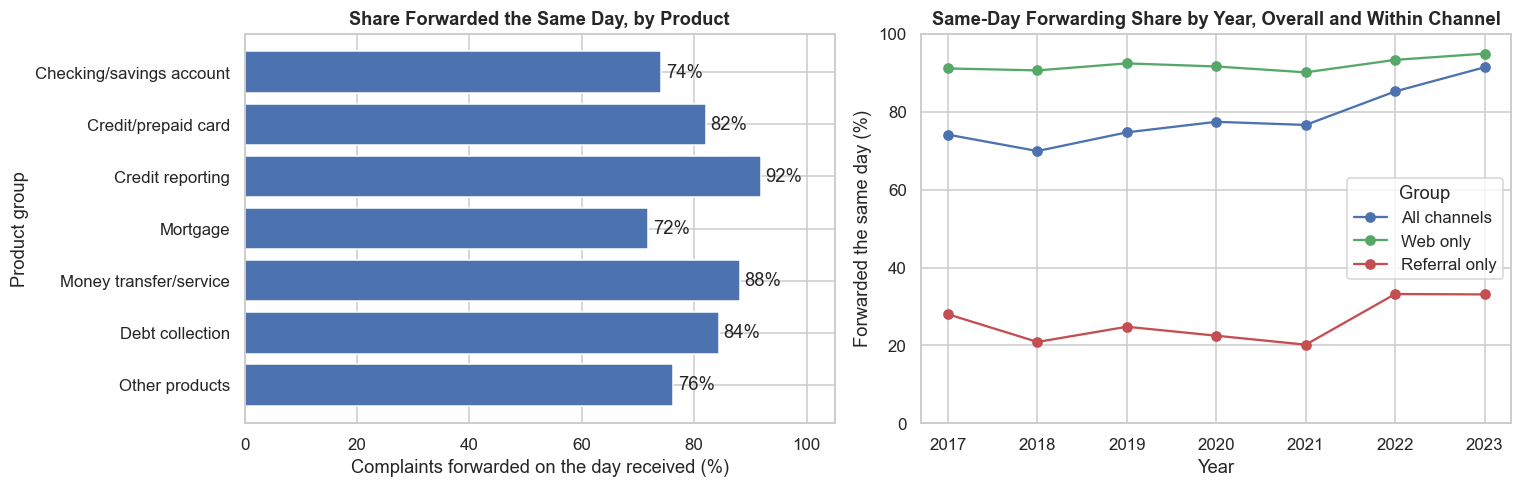

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
sd = tbl3["same_day"].loc[PRODUCT_ORDER[::-1]]
bars = axes[0].barh(sd.index, sd.values, color=PAL[0])
axes[0].bar_label(bars, labels=[f"{v:.0f}%" for v in sd.values], padding=3)
axes[0].set_title("Share Forwarded the Same Day, by Product")
axes[0].set_xlabel("Complaints forwarded on the day received (%)")
axes[0].set_ylabel("Product group")
axes[0].set_xlim(0, 105)
by_year[["same_day_all", "same_day_Web_only", "same_day_Referral_only"]].plot(ax=axes[1], marker="o", color=[PAL[0], PAL[2], PAL[3]])
axes[1].set_title("Same-Day Forwarding Share by Year, Overall and Within Channel")
axes[1].set_xlabel("Year")
axes[1].set_ylabel("Forwarded the same day (%)")
axes[1].legend(["All channels", "Web only", "Referral only"], title="Group")
axes[1].set_ylim(0, 100)
save_fig("16_h3_forwarding")

**Interpretation (H3): forwarding intervals differ mainly by submission channel, not by product.**

- **Product (H3a):** statistically significant (H = 1,508, p < 0.001) but only a **small** effect (epsilon-squared = 0.024). The same-day share ranges from 72% (mortgage) and 74% (checking/savings) to 92% (credit reporting).
- **Channel (H3b):** a **large** effect (epsilon-squared = 0.364). **92.2% of web complaints are forwarded the same day, versus 24.6% of referral complaints** (referral median = 1 day). There is an 83% chance that a randomly chosen referral complaint takes longer to forward than a randomly chosen web complaint.
- **Confounding check (H3c):** referral complaints make up 27% of mortgage and 25% of checking/savings complaints but only 1.5% of credit-reporting complaints. When the comparison is restricted to a single channel, the product effect shrinks by about 85% (epsilon-squared 0.0037 within web-only and 0.0035 within referral-only, versus 0.024 overall). **Most of the product difference is therefore a channel-mix effect.**
- **Over time:** the overall same-day share rose from 69.9% (2018) to 91.4% (2023). Within channels it barely moved (web-only 90-95%, referral-only 20-33%); what changed is the mix, with the referral share falling from 27.1% (2018) to 4.0% (2023). The apparent improvement is largely a shift toward web submissions, not faster handling within a channel.

**Remember:** this interval ends when the CFPB forwards the complaint. It says nothing about how quickly the company responds or resolves it. The dictionary does not define "Referral", so its meaning cannot be confirmed from the file.

### 6.4 H4: Are recorded response categories associated with product (and issue)?

The test uses the three main closed categories. *In progress* (1,494) is excluded because no response has been recorded yet, and *Closed (no detail)* (8) is excluded because its expected counts are far below 5. Both exclusions are documented.

In [35]:
done = df[df["company_response"].isin(["Closed with explanation", "Closed with monetary relief", "Closed with non-monetary relief"])].copy()
RESP_ORDER = ["Closed with explanation", "Closed with monetary relief", "Closed with non-monetary relief"]
print(f"Records in the test: {len(done):,} (excluded: In progress = {df['is_in_progress'].sum():,}, Closed (no detail) = 8)")

ct4 = pd.crosstab(done["product_group"], done["company_response"]).loc[PRODUCT_ORDER, RESP_ORDER]
display(ct4)
r4 = chi2_test(ct4)
print(f"Assumption check: minimum expected count = {r4['min_expected']:.1f}; cells < 5: {r4['pct_cells_expected_lt5']:.0f}%")
print(f"Chi-square = {r4['chi2']:,.1f}, df = {r4['dof']}, {fmt_p(r4['p'])}, {v_text(r4)}")
log_result("H4a", "Chi-square: response category x product", f"chi2 = {r4['chi2']:,.0f}, df = {r4['dof']}", r4["p"], v_text(r4), "Reject H0: small-to-medium association (V sits at the 0.21 'medium' cut-off)")

rate = []
for p in PRODUCT_ORDER:
    k = ct4.loc[p, "Closed with monetary relief"]; n = ct4.loc[p].sum(); lo, hi = wilson_ci(k, n)
    rate.append({"product_group": p, "n_closed": n, "monetary_relief_pct": k / n * 100, "ci_low": lo * 100, "ci_high": hi * 100,
                 "non_monetary_pct": ct4.loc[p, "Closed with non-monetary relief"] / n * 100})
rate = pd.DataFrame(rate).set_index("product_group").round(1)
display(rate)

Records in the test: 61,014 (excluded: In progress = 1,494, Closed (no detail) = 8)


company_response,Closed with explanation,Closed with monetary relief,Closed with non-monetary relief
product_group,,,
Checking/savings account,14836,8027,1241
Credit/prepaid card,9361,4798,1621
Credit reporting,6067,273,1178
Mortgage,4928,750,876
Money transfer/service,2709,634,41
Debt collection,2367,111,209
Other products,776,104,107


Assumption check: minimum expected count = 85.3; cells < 5: 0%
Chi-square = 5,426.0, df = 12, p < 0.001, Cramer's V = 0.211 (small effect)


,n_closed,monetary_relief_pct,ci_low,ci_high,non_monetary_pct
product_group,,,,,
Checking/savings account,24104,33.3,32.7,33.9,5.1
Credit/prepaid card,15780,30.4,29.7,31.1,10.3
Credit reporting,7518,3.6,3.2,4.1,15.7
Mortgage,6554,11.4,10.7,12.2,13.4
Money transfer/service,3384,18.7,17.5,20.1,1.2
Debt collection,2687,4.1,3.4,5.0,7.8
Other products,987,10.5,8.8,12.6,10.8


In [36]:
# Issue-level association (top 10 issues) and a stratified check inside one product
top10_issues = done["issue"].value_counts().head(10).index
ct4b = pd.crosstab(done.loc[done["issue"].isin(top10_issues), "issue"], done.loc[done["issue"].isin(top10_issues), "company_response"])[RESP_ORDER]
r4b = chi2_test(ct4b)
print(f"(b) TOP-10 ISSUES x response: chi2 = {r4b['chi2']:,.0f}, df = {r4b['dof']}, {fmt_p(r4b['p'])}, {v_text(r4b)}, min expected = {r4b['min_expected']:.0f}")
log_result("H4b", "Chi-square: response category x top-10 issues", f"chi2 = {r4b['chi2']:,.0f}, df = {r4b['dof']}", r4b["p"], v_text(r4b), "Reject H0 (issue and product overlap, so partly the same signal)")

chk = done[done["product_group"] == "Checking/savings account"]
top5_chk = chk["issue"].value_counts().head(5).index
ct4c = pd.crosstab(chk.loc[chk["issue"].isin(top5_chk), "issue"], chk.loc[chk["issue"].isin(top5_chk), "company_response"])[RESP_ORDER]
r4c = chi2_test(ct4c)
print(f"(c) STRATIFIED: top-5 issues WITHIN checking/savings: chi2 = {r4c['chi2']:,.0f}, df = {r4c['dof']}, {fmt_p(r4c['p'])}, {v_text(r4c)}")
mr_issue = (pd.crosstab(chk.loc[chk["issue"].isin(top5_chk), "issue"], chk.loc[chk["issue"].isin(top5_chk), "company_response"], normalize="index")["Closed with monetary relief"] * 100).round(1)
display(mr_issue.sort_values(ascending=False).rename("% monetary relief (checking/savings only)").to_frame())
log_result("H4c", "Chi-square: response x top-5 issues within checking/savings", f"chi2 = {r4c['chi2']:,.0f}, df = {r4c['dof']}", r4c["p"], v_text(r4c), "Association persists within a single product")

(b) TOP-10 ISSUES x response: chi2 = 5,735, df = 18, p < 0.001, Cramer's V = 0.267 (medium effect), min expected = 133
(c) STRATIFIED: top-5 issues WITHIN checking/savings: chi2 = 1,733, df = 8, p < 0.001, Cramer's V = 0.190 (small effect)


,% monetary relief (checking/savings only)
issue,
Problem caused by your funds being low,49.3
Problem with a lender or other company charging your account,40.8
Managing an account,35.3
Closing an account,31.0
Opening an account,11.8


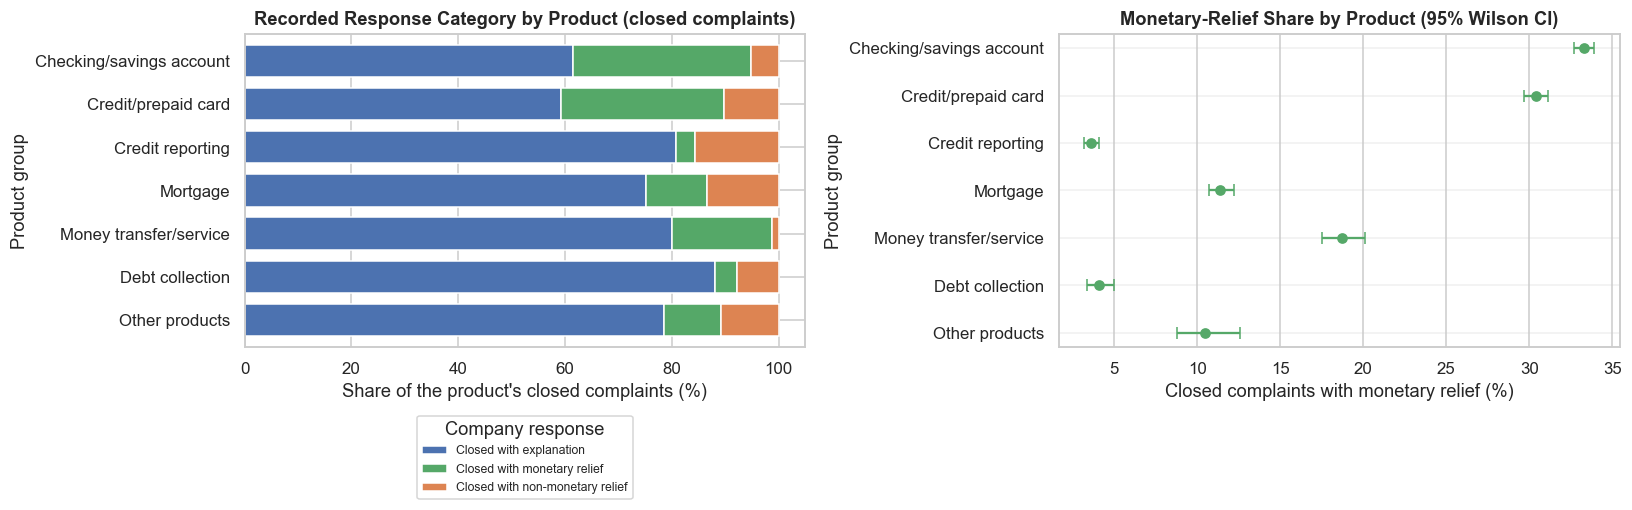

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
share4 = (ct4.div(ct4.sum(axis=1), axis=0) * 100).loc[PRODUCT_ORDER[::-1]]
share4.plot(kind="barh", stacked=True, ax=axes[0], color=[PAL[0], PAL[2], PAL[1]], width=0.75)
axes[0].set_title("Recorded Response Category by Product (closed complaints)")
axes[0].set_xlabel("Share of the product's closed complaints (%)")
axes[0].set_ylabel("Product group")
axes[0].legend(title="Company response", fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.2))
rr = rate.loc[PRODUCT_ORDER[::-1]]
axes[1].errorbar(rr["monetary_relief_pct"], range(len(rr)), xerr=[rr["monetary_relief_pct"] - rr["ci_low"], rr["ci_high"] - rr["monetary_relief_pct"]],
                 fmt="o", color=PAL[2], capsize=4)
axes[1].set_yticks(range(len(rr))); axes[1].set_yticklabels(rr.index)
axes[1].set_title("Monetary-Relief Share by Product (95% Wilson CI)")
axes[1].set_xlabel("Closed complaints with monetary relief (%)")
axes[1].set_ylabel("Product group")
axes[1].grid(axis="y", alpha=0.3)
save_fig("17_h4_response_by_product")

**Interpretation (H4): reject H0. Recorded response categories are associated with product, and with issue.**

- **Product (H4a):** chi-square = 5,426 (df = 12), p < 0.001, Cramer's V = 0.211, which sits at the small/medium boundary (0.21). The test uses 61,014 closed complaints, with *In progress* (1,494) and *Closed (no detail)* (8) excluded as documented.
- **Share closed with monetary relief:** checking/savings 33.3%, credit/prepaid card 30.4%, money transfer 18.7%, mortgage 11.4%, other products 10.5%, debt collection 4.1%, **credit reporting 3.6%**. Credit reporting and mortgage have the highest non-monetary-relief shares (15.7% and 13.4%), and debt collection (88.1%) and credit reporting (80.7%) the highest *closed with explanation* shares.
- **Issue (H4b):** V = 0.267 (medium) across the ten most common issues. Because issues are nested within products (the dictionary says issue values depend on product), this is partly the same signal as H4a.
- **Stratified check (H4c):** within checking/savings alone the association persists (V = 0.190). Monetary relief ranges from 49.3% for *Problem caused by your funds being low* and 40.8% for *charging your account* down to 11.8% for *Opening an account*. So both product and issue matter.

**Interpretation in context.** Remedies that involve money (refunding a fee or charge) are a natural fit for deposit-account and card issues, while credit-reporting complaints are more often resolved by explanation or correcting information. That is a plausible reading, not something the data prove. A recorded response category is the company's classification: it does **not** show that the company was at fault or that the consumer was right.

### 6.5 H5: Has the share of "not timely" responses changed over time?

Only complaints with a **determined** timeliness status (Yes or No) are used. *In progress* complaints (blank) are excluded, not counted as "No".

In [38]:
det = df[df["timely_status"].isin(["Timely", "Not timely"])]
ct5 = pd.crosstab(det["year"], det["timely_status"])[["Timely", "Not timely"]]
r5 = chi2_test(ct5)
tbl5 = ct5.copy()
tbl5["n"] = tbl5.sum(axis=1)
tbl5["not_timely_pct"] = (tbl5["Not timely"] / tbl5["n"] * 100).round(2)
ci = [wilson_ci(k, n) for k, n in zip(tbl5["Not timely"], tbl5["n"])]
tbl5["ci_low_pct"] = [round(c[0] * 100, 2) for c in ci]; tbl5["ci_high_pct"] = [round(c[1] * 100, 2) for c in ci]
display(tbl5)
print(f"Assumption check: minimum expected count = {r5['min_expected']:.1f} (met)")
print(f"Chi-square = {r5['chi2']:,.1f}, df = {r5['dof']}, {fmt_p(r5['p'])}, {v_text(r5)}")
log_result("H5", "Chi-square: timeliness x year", f"chi2 = {r5['chi2']:,.0f}, df = {r5['dof']}", r5["p"], v_text(r5), "Reject H0: not-timely share changed")

# Where is the excess concentrated?
surge_months = [str(m) for m in nt_month[nt_month > 10].index]
nt = det[det["timely_status"] == "Not timely"]
nt_surge = nt[nt["year_month"].astype(str).isin(surge_months)]
print()
print(f"Months with > 10% not timely: {surge_months}")
print(f"Those months hold {len(nt_surge):,} of the {len(nt):,} 'Not timely' records ({len(nt_surge) / len(nt):.0%}) but only {det['year_month'].astype(str).isin(surge_months).mean():.1%} of determined complaints")
comp = pd.DataFrame({"not_timely_in_surge_months_%": nt_surge["product_group"].value_counts(normalize=True) * 100,
                     "all_determined_complaints_%": det["product_group"].value_counts(normalize=True) * 100}).loc[PRODUCT_ORDER].round(1)
display(comp)
rate_prod = det.groupby("product_group")["timely_status"].apply(lambda s: (s == "Not timely").mean() * 100).loc[PRODUCT_ORDER].round(1)
rate_prod_2021 = det[det["year"] == 2021].groupby("product_group")["timely_status"].apply(lambda s: (s == "Not timely").mean() * 100).loc[PRODUCT_ORDER].round(1)
display(pd.DataFrame({"not_timely_% (all years)": rate_prod, "not_timely_% (2021 only)": rate_prod_2021}))

timely_status,Timely,Not timely,n,not_timely_pct,ci_low_pct,ci_high_pct
year,,,,,,
2017,5385,9,5394,0.17,0.09,0.32
2018,7860,12,7872,0.15,0.09,0.27
2019,7068,7,7075,0.10,0.05,0.20
2020,8880,62,8942,0.69,0.54,0.89
2021,9925,1224,11149,10.98,10.41,11.57
2022,12386,567,12953,4.38,4.04,4.74
2023,7115,522,7637,6.84,6.29,7.42


Assumption check: minimum expected count = 212.4 (met)
Chi-square = 2,662.5, df = 6, p < 0.001, Cramer's V = 0.209 (small effect)

Months with > 10% not timely: ['2021-06', '2021-07', '2021-08', '2021-09', '2021-10', '2023-01', '2023-02', '2023-03']
Those months hold 1,462 of the 2,403 'Not timely' records (61%) but only 13.1% of determined complaints


,not_timely_in_surge_months_%,all_determined_complaints_%
product_group,,
Checking/savings account,31.9,39.5
Credit/prepaid card,29.1,25.9
Credit reporting,23.0,12.3
Mortgage,0.4,10.7
Money transfer/service,5.4,5.5
Debt collection,8.5,4.4
Other products,1.7,1.6


,not_timely_% (all years),not_timely_% (2021 only)
product_group,,
Checking/savings account,3.6,7.8
Credit/prepaid card,4.4,12.6
Credit reporting,6.3,18.6
Mortgage,0.2,0.4
Money transfer/service,4.1,10.4
Debt collection,6.4,19.5
Other products,4.4,9.8


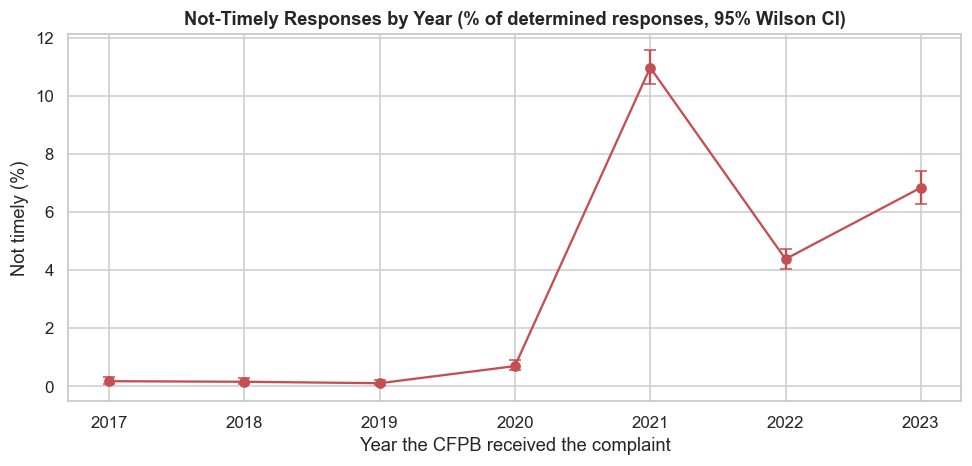

In [39]:
fig, ax = plt.subplots(figsize=(9, 4.4))
ax.errorbar(tbl5.index.astype(str), tbl5["not_timely_pct"], yerr=[tbl5["not_timely_pct"] - tbl5["ci_low_pct"], tbl5["ci_high_pct"] - tbl5["not_timely_pct"]],
            fmt="o-", color=PAL[3], capsize=4)
ax.set_title("Not-Timely Responses by Year (% of determined responses, 95% Wilson CI)")
ax.set_xlabel("Year the CFPB received the complaint")
ax.set_ylabel("Not timely (%)")
save_fig("18_h5_not_timely_by_year")

**Interpretation (H5): reject H0. The share of "not timely" responses changed sharply over time.**

- Chi-square = 2,663 (df = 6), p < 0.001, Cramer's V = 0.209.
- **Not timely, as a share of determined responses:** 0.17% (2017), 0.15% (2018), 0.10% (2019), 0.69% (2020), **10.98% (2021)**, 4.38% (2022) and 6.83% (2023). Overall, **96.06%** of determined responses (93.77% of all complaints) are recorded as timely.
- **The deviation is concentrated:** eight months (June-October 2021 and January-March 2023) contain **61% of all "not timely" records but only 13.1% of determined complaints**. The peak was June 2021, when 41.6% of determined responses were not timely.
- **It is not uniform across products.** In 2021 the not-timely share was 19.5% for debt collection, 18.6% for credit reporting, 12.6% for credit/prepaid card, 7.8% for checking/savings and only 0.4% for mortgage.
- **It is not simply a volume surge.** June 2021 had 934 complaints, close to the 854 in May 2021.

**Caveats and alternative explanations.** All 1,494 *In progress* complaints are from 2023 (49% of July and 82% of August 2023 complaints are still open), so timeliness for the most recent months is incomplete. The very low not-timely share from May to August 2023 may partly reflect that. The data cannot reveal the cause of the 2021 and early-2023 episodes: an operational backlog, a process or system change, a change in how timeliness was recorded, or a product-specific issue are all possible. The indicator itself cannot be audited because no response dates are supplied.

### 6.6 H6: Has the composition of recorded response categories changed over time?

Same closed-complaint population as H4. *In progress* complaints exist only in 2023 (they are recent and still open), so including them would make 2023 look different for a reason unrelated to the company's response pattern.

In [40]:
ct6 = pd.crosstab(done["year"], done["company_response"])[RESP_ORDER]
r6 = chi2_test(ct6)
share6 = (ct6.div(ct6.sum(axis=1), axis=0) * 100).round(1)
display(share6)
print(f"Assumption check: minimum expected count = {r6['min_expected']:.1f} (met)")
print(f"Chi-square = {r6['chi2']:,.1f}, df = {r6['dof']}, {fmt_p(r6['p'])}, {v_text(r6)}")
log_result("H6", "Chi-square: response category x year", f"chi2 = {r6['chi2']:,.0f}, df = {r6['dof']}", r6["p"], v_text(r6), "Reject H0 statistically, but negligible-to-small effect")

# Monetary-relief share trend over complete months
mr_m = done.groupby("year_month")["company_response"].apply(lambda s: (s == "Closed with monetary relief").mean() * 100)
mr_m = mr_m[mr_m.index <= pd.Period("2023-07", "M")]
tau6, p6 = stats.kendalltau(np.arange(len(mr_m)), mr_m.values)
print(f"Monthly monetary-relief share: Kendall tau = {tau6:.2f}, {fmt_p(p6)}  (a value near 0 means no monotonic trend)")
log_result("H6b", "Kendall tau: monthly monetary-relief share", f"tau = {tau6:.2f}", p6, "monotonic trend", "No trend" if p6 >= ALPHA else ("Weak downward drift; not significant after Bonferroni" if p6 >= BONFERRONI_ALPHA else "Downward trend"))

ci6 = [wilson_ci(k, n) for k, n in zip(ct6["Closed with monetary relief"], ct6.sum(axis=1))]
mr_year = pd.DataFrame({"monetary_pct": share6["Closed with monetary relief"], "lo": [c[0] * 100 for c in ci6], "hi": [c[1] * 100 for c in ci6]})

company_response,Closed with explanation,Closed with monetary relief,Closed with non-monetary relief
year,,,
2017,69.2,22.5,8.3
2018,67.0,25.3,7.6
2019,67.3,24.5,8.2
2020,66.5,25.3,8.2
2021,68.8,25.2,5.9
2022,65.5,23.5,11.0
2023,67.8,21.4,10.8


Assumption check: minimum expected count = 466.2 (met)
Chi-square = 294.4, df = 12, p < 0.001, Cramer's V = 0.049 (negligible effect)
Monthly monetary-relief share: Kendall tau = -0.17, p = 0.031  (a value near 0 means no monotonic trend)


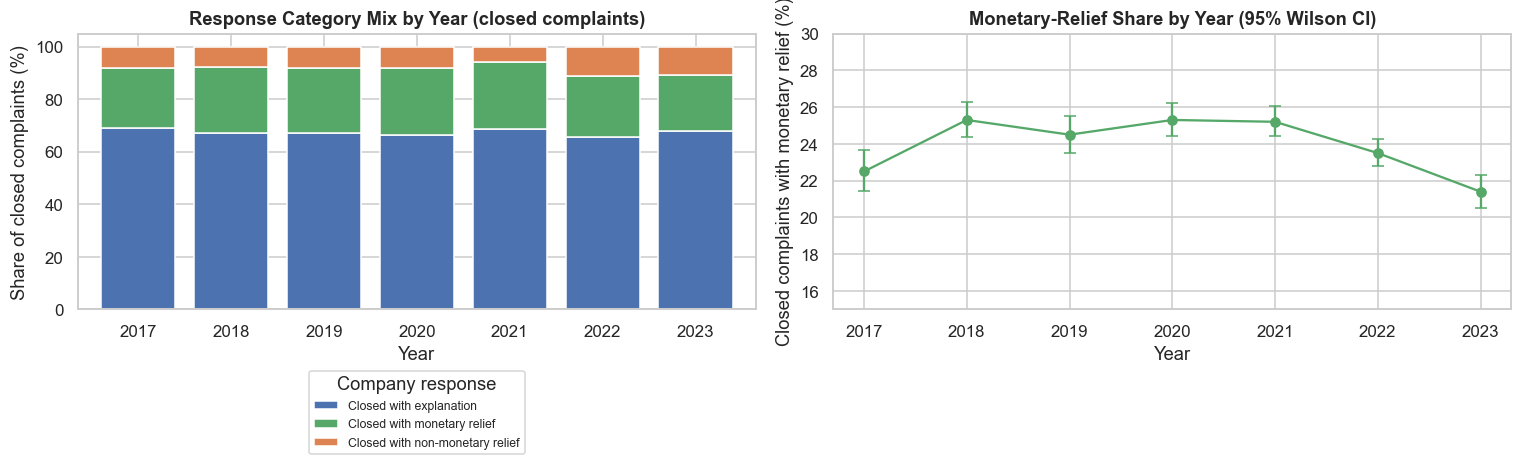

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
share6[RESP_ORDER].plot(kind="bar", stacked=True, ax=axes[0], color=[PAL[0], PAL[2], PAL[1]], width=0.8)
axes[0].set_title("Response Category Mix by Year (closed complaints)")
axes[0].set_xlabel("Year")
axes[0].set_ylabel("Share of closed complaints (%)")
axes[0].legend(title="Company response", fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.2))
axes[0].tick_params(axis="x", rotation=0)
axes[1].errorbar(mr_year.index.astype(str), mr_year["monetary_pct"], yerr=[mr_year["monetary_pct"] - mr_year["lo"], mr_year["hi"] - mr_year["monetary_pct"]], fmt="o-", color=PAL[2], capsize=4)
axes[1].set_title("Monetary-Relief Share by Year (95% Wilson CI)")
axes[1].set_xlabel("Year")
axes[1].set_ylabel("Closed complaints with monetary relief (%)")
axes[1].set_ylim(15, 30)
save_fig("19_h6_response_over_time")

**Interpretation (H6): statistically significant, but the practical change is negligible.**

- Chi-square = 294 (df = 12), p < 0.001, but Cramer's V = **0.049 (negligible)**. With 61,014 records, even trivial shifts become significant.
- Across the seven years, *closed with explanation* stayed between 65.5% and 69.2%, *monetary relief* between 21.4% and 25.3%, and *non-monetary relief* between 5.9% and 11.0%. The only visible movement is a dip in non-monetary relief in 2021 (5.9%) followed by a rise to about 11% in 2022-2023, and monetary relief easing from 25.2% (2021) to 21.4% (2023).
- The monthly monetary-relief share shows a weak downward drift (Kendall tau = -0.17, p = 0.031), which is **not** significant after the Bonferroni adjustment (threshold 0.0083) and is likely inflated by autocorrelation.

**Conclusion:** the recorded response mix has been **broadly stable**. The 2023 composition excludes the 1,494 open complaints.

### 6.7 Summary of all statistical tests

In [42]:
res = pd.DataFrame(RESULTS)
res["p_value_display"] = res["p_value"].apply(lambda p: "< 0.001" if p < 0.001 else f"{p:.3f}")
res["significant_at_0.05"] = res["p_value"] < ALPHA
res["significant_after_Bonferroni_(0.0083)"] = res["p_value"] < BONFERRONI_ALPHA
display(res[["hypothesis", "test", "statistic", "p_value_display", "effect_size", "significant_at_0.05", "significant_after_Bonferroni_(0.0083)", "conclusion"]])
res.drop(columns=["p_value_display"]).to_csv("data/processed/statistical_test_summary.csv", index=False)
print("Saved: data/processed/statistical_test_summary.csv")

,hypothesis,test,statistic,p_value_display,effect_size,significant_at_0.05,significant_after_Bonferroni_(0.0083),conclusion
0,H1,"Kendall tau trend, 75 monthly counts",tau = 0.59,< 0.001,Theil-Sen slope +8.2/month (block-bootstrap 95...,True,True,Reject H0: upward trend
1,H1,"Kruskal-Wallis, monthly counts 2018-2022",H = 44.4,< 0.001,epsilon-squared = 0.75 (large),True,True,Reject H0: years differ
2,H1,"Kruskal-Wallis, seasonality (calendar month)",H = 12.4,0.336,detrended ratios,False,False,Seasonality not significant
3,H2,Chi-square: product group x year,"chi2 = 2,871, df = 36",< 0.001,Cramer's V = 0.087 (small effect),True,True,Reject H0: product mix changed (small effect)
4,H3a,Kruskal-Wallis: forwarding days by product,H = 1508,< 0.001,epsilon-squared = 0.0241 (small),True,True,"Significant, but small effect"
5,H3b,Kruskal-Wallis: forwarding days by channel,H = 22750,< 0.001,epsilon-squared = 0.364 (large); Referral vs W...,True,True,Reject H0: channel matters (large effect)
6,H3c,Kruskal-Wallis: forwarding days by year,H = 1653,< 0.001,epsilon-squared = 0.0264 (small),True,True,"Significant, small effect; channel mix is a co..."
7,H4a,Chi-square: response category x product,"chi2 = 5,426, df = 12",< 0.001,Cramer's V = 0.211 (small effect),True,True,Reject H0: small-to-medium association (V sits...
8,H4b,Chi-square: response category x top-10 issues,"chi2 = 5,735, df = 18",< 0.001,Cramer's V = 0.267 (medium effect),True,True,"Reject H0 (issue and product overlap, so partl..."
9,H4c,Chi-square: response x top-5 issues within che...,"chi2 = 1,733, df = 8",< 0.001,Cramer's V = 0.190 (small effect),True,True,Association persists within a single product


Saved: data/processed/statistical_test_summary.csv


### 6.8 Sensitivity analysis: do the conclusions depend on the near-duplicates or the July 2023 spike?

The main results are recomputed under four data scenarios. If a conclusion survives all four, it is robust to those two judgement calls.

In [43]:
def key_stats(frame, drop_jul_2023=False):
    m = frame.groupby("year_month").size()
    m = m[m.index <= pd.Period("2023-07", "M")]
    if drop_jul_2023:
        m = m.drop(pd.Period("2023-07", "M"), errors="ignore")
    t_ = np.arange(len(m))
    tau_ = stats.kendalltau(t_, m.values)[0]
    slope_ = stats.theilslopes(m.values.astype(float), t_)[0]
    v2 = chi2_test(pd.crosstab(frame["product_group"], frame["year"]))["cramers_v"]
    ch = frame[frame["submitted_via"].isin(channels)]
    Hc = stats.kruskal(*[ch.loc[ch["submitted_via"] == c, "forwarding_days"].values for c in channels])[0]
    dn = frame[frame["company_response"].isin(RESP_ORDER)]
    v4 = chi2_test(pd.crosstab(dn["product_group"], dn["company_response"]))["cramers_v"]
    v6 = chi2_test(pd.crosstab(dn["year"], dn["company_response"]))["cramers_v"]
    dt = frame[frame["timely_status"].isin(["Timely", "Not timely"])]
    v5 = chi2_test(pd.crosstab(dt["year"], dt["timely_status"]))["cramers_v"]
    nt21 = (dt.loc[dt["year"] == 2021, "timely_status"] == "Not timely").mean() * 100
    return {"records": len(frame), "H1 tau": tau_, "H1 slope/month": slope_, "H2 V (product x year)": v2,
            "H3 eps2 (channel)": epsilon_squared(Hc, len(ch)), "H4 V (response x product)": v4,
            "H5 V (timely x year)": v5, "H5 not-timely % in 2021": nt21, "H6 V (response x year)": v6}

jul = pd.Period("2023-07", "M")
scenarios = {
    "All records": key_stats(df),
    "Near-duplicates removed": key_stats(df[~df["flag_near_duplicate"]]),
    "July 2023 excluded": key_stats(df[df["year_month"] != jul], drop_jul_2023=True),
    "Both removed": key_stats(df[(~df["flag_near_duplicate"]) & (df["year_month"] != jul)], drop_jul_2023=True),
}
sens = pd.DataFrame(scenarios).T
display(sens.round(3))
sens.round(4).to_csv("data/processed/sensitivity_analysis.csv")
spread = (sens.max() - sens.min())
print("Largest change across scenarios in each statistic:")
display(spread.round(3).rename("max - min").to_frame().T)

,records,H1 tau,H1 slope/month,H2 V (product x year),H3 eps2 (channel),H4 V (response x product),H5 V (timely x year),H5 not-timely % in 2021,H6 V (response x year)
All records,62516.0,0.592,8.243,0.087,0.364,0.211,0.209,10.979,0.049
Near-duplicates removed,61022.0,0.590,7.806,0.085,0.363,0.210,0.207,10.807,0.049
July 2023 excluded,60767.0,0.581,7.934,0.087,0.363,0.212,0.212,10.979,0.050
Both removed,59338.0,0.579,7.541,0.084,0.362,0.211,0.211,10.807,0.050


Largest change across scenarios in each statistic:


,records,H1 tau,H1 slope/month,H2 V (product x year),H3 eps2 (channel),H4 V (response x product),H5 V (timely x year),H5 not-timely % in 2021,H6 V (response x year)
max - min,3178.0,0.013,0.702,0.003,0.002,0.002,0.005,0.172,0.001


## 7. Forecasting Feasibility (business question 9)

This is a **feasibility check, not a production forecast**. Simple methods are compared on data they have not seen:

- **Rolling one-step-ahead:** at each month from January 2021, forecast the next month using only earlier data.
- **Six-month hold-out:** train through December 2022, forecast January to June 2023.
- The July 2023 spike is reported separately because it is an unforecastable shock.

Methods: *Naive* (last value), *Seasonal naive* (same month last year), *3-month and 6-month moving averages*, and *Linear trend* (fitted on the last 24 months).

In [44]:
def forecast(train, h, method):
    v = np.asarray(train, dtype=float)
    if method == "Naive":
        return np.repeat(v[-1], h)
    if method == "Seasonal naive":
        return np.array([v[len(v) - 12 + (i % 12)] for i in range(h)])
    if method == "Moving average (3)":
        return np.repeat(v[-3:].mean(), h)
    if method == "Moving average (6)":
        return np.repeat(v[-6:].mean(), h)
    if method == "Linear trend (24 mo)":
        w = v[-24:]; tt = np.arange(len(w)); b, a = np.polyfit(tt, w, 1)
        return a + b * (len(w) + np.arange(h))
    raise ValueError(method)

METHODS = ["Naive", "Seasonal naive", "Moving average (3)", "Moving average (6)", "Linear trend (24 mo)"]
vals = monthly.values.astype(float)
idx = monthly.index

def metrics(actual, pred):
    actual = np.asarray(actual); pred = np.asarray(pred)
    return {"MAE": np.mean(np.abs(actual - pred)), "MAPE_%": np.mean(np.abs(actual - pred) / actual) * 100}

# Rolling one-step-ahead from Jan 2021 to Jun 2023 (excluding the July 2023 spike), then the spike month separately
start = list(idx).index(pd.Period("2021-01", "M")); end = list(idx).index(pd.Period("2023-06", "M"))
roll = {m: [] for m in METHODS}; act = []
for i in range(start, end + 1):
    act.append(vals[i])
    for m in METHODS:
        roll[m].append(forecast(vals[:i], 1, m)[0])
roll_tbl = pd.DataFrame({m: metrics(act, roll[m]) for m in METHODS}).T.round(1)
print(f"ROLLING ONE-STEP-AHEAD ({len(act)} months, Jan 2021 - Jun 2023)")
display(roll_tbl.sort_values("MAPE_%"))

# Six-month hold-out
cut = list(idx).index(pd.Period("2022-12", "M")) + 1
train, test = vals[:cut], vals[cut:cut + 6]
hold = {m: forecast(train, 6, m) for m in METHODS}
hold_tbl = pd.DataFrame({m: metrics(test, hold[m]) for m in METHODS}).T.round(1)
print("SIX-MONTH HOLD-OUT (train to Dec 2022, forecast Jan - Jun 2023)")
display(hold_tbl.sort_values("MAPE_%"))

# The July 2023 spike
jul_actual = vals[-1]
jul_fc = {m: forecast(vals[:-1], 1, m)[0] for m in METHODS}
print(f"July 2023 actual = {jul_actual:,.0f}.  One-step forecasts: " + ", ".join(f"{m} {v:,.0f}" for m, v in jul_fc.items()))
print(f"  Best method misses the spike by about {min(abs(jul_actual - v) for v in jul_fc.values()):,.0f} complaints ({min(abs(jul_actual - v) for v in jul_fc.values()) / jul_actual:.0%} of the actual value)")

ROLLING ONE-STEP-AHEAD (30 months, Jan 2021 - Jun 2023)


,MAE,MAPE_%
Moving average (3),79.3,7.6
Naive,79.1,7.7
Moving average (6),81.8,7.9
Linear trend (24 mo),91.8,9.1
Seasonal naive,161.4,15.4


SIX-MONTH HOLD-OUT (train to Dec 2022, forecast Jan - Jun 2023)


,MAE,MAPE_%
Moving average (3),71.9,6.6
Naive,74.8,6.9
Moving average (6),78.1,7.2
Linear trend (24 mo),91.2,8.4
Seasonal naive,112.7,10.0


July 2023 actual = 1,749.  One-step forecasts: Naive 1,018, Seasonal naive 1,044, Moving average (3) 1,054, Moving average (6) 1,111, Linear trend (24 mo) 1,186
  Best method misses the spike by about 563 complaints (32% of the actual value)


**Visualization 20 – Hold-out forecasts versus actual monthly complaints.**

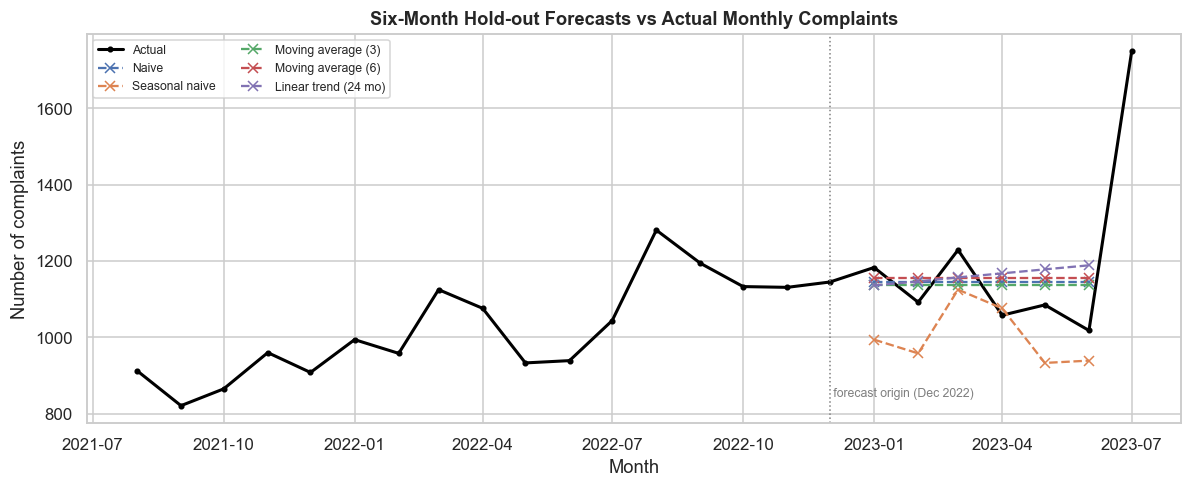

In [45]:
fig, ax = plt.subplots(figsize=(11, 4.6))
hist_idx = idx[-24:]
ax.plot(hist_idx.to_timestamp(), vals[-24:], color="black", lw=2, marker="o", ms=3, label="Actual")
test_idx = idx[cut:cut + 6]
for m, col in zip(METHODS, PAL):
    ax.plot(test_idx.to_timestamp(), hold[m], ls="--", marker="x", color=col, label=m)
ax.axvline(idx[cut - 1].to_timestamp(), color="grey", ls=":", lw=1)
ax.text(idx[cut - 1].to_timestamp(), vals[-24:].min() * 1.02, " forecast origin (Dec 2022)", fontsize=8, color="grey", va="bottom")
ax.set_title("Six-Month Hold-out Forecasts vs Actual Monthly Complaints")
ax.set_xlabel("Month")
ax.set_ylabel("Number of complaints")
ax.legend(fontsize=8, ncol=2)
save_fig("20_forecast_holdout")

**Interpretation (business question 9): partly. History supports short-horizon forecasting in normal months, but not shocks.**

- **Rolling one-step-ahead (30 months):** a 3-month moving average had the lowest error (MAPE 7.6%), essentially tied with the naive forecast (7.7%) and the 6-month average (7.9%). The linear trend was worse (9.1%) and the **seasonal naive forecast was the worst (15.4%)**, consistent with the finding that there is no significant seasonality.
- **Six-month hold-out (January-June 2023):** moving average (3) again led with a MAPE of 6.6%.
- **The July 2023 spike was unforecastable:** all methods predicted 1,018 to 1,186 against an actual 1,749. The best miss was 563 complaints (32% of the actual).

**Practical reading.** A simple recent-average baseline is good enough for planning the next month in ordinary conditions, with typical error of about 7-8%. It cannot anticipate spikes, so any monitoring tool should pair it with an **anomaly alert** (for example, flag days far above the usual daily median of 27). This is a feasibility check on 30 evaluation months with one major shock and no external drivers, so it should not be used for long-horizon forecasts.

## 8. Findings, Limitations and Alternative Explanations

In [46]:
best_roll = roll_tbl["MAPE_%"].idxmin()
print("KEY NUMBERS FOR THE REPORT")
print(f"  Records                    : {len(df):,}  ({df['date_received_by_cfpb'].min().date()} to {df['date_received_by_cfpb'].max().date()})")
print(f"  Normalised monthly volume  : " + ", ".join(f"{y}: {v:,.0f}" for y, v in annual["avg_per_month_normalised"].items()))
print(f"  Top product                : {prod.index[0]} ({prod.iloc[0] / len(df):.1%});  top 3 = {prod.head(3).sum() / len(df):.1%}")
print(f"  Top issue                  : {df['issue'].value_counts().index[0]} ({df['issue'].value_counts(normalize=True).iloc[0]:.1%})")
print(f"  Same-day forwarding        : {(df['forwarding_days'] == 0).mean():.1%};  median {df['forwarding_days'].median():.0f} day(s)")
print(f"  Closed with explanation    : {(df['company_response'] == 'Closed with explanation').mean():.1%};  monetary relief {(df['company_response'] == 'Closed with monetary relief').mean():.1%};  non-monetary {(df['company_response'] == 'Closed with non-monetary relief').mean():.1%}")
print(f"  Timely (of determined)     : {n_yes / (n_yes + n_no):.2%};  of all {n_yes / len(df):.2%}")
print(f"  Best rolling forecast      : {best_roll} (MAPE {roll_tbl.loc[best_roll, 'MAPE_%']:.1f}%)")

summary_lines = [
    f"Records: {len(df):,}",
    f"Trend (Kendall tau): {tau:.2f}; Theil-Sen slope {ts_slope:+.1f}/month",
    f"Product x year Cramer's V: {r2['cramers_v']:.3f}",
    f"Response x product Cramer's V: {r4['cramers_v']:.3f}",
    f"Not timely x year Cramer's V: {r5['cramers_v']:.3f}",
    f"Raw file SHA-256: {FILE_SHA256}",
]
with open("data/processed/analysis_summary.txt", "w") as f:
    f.write("\n".join(summary_lines))

KEY NUMBERS FOR THE REPORT
  Records                    : 62,516  (2017-05-01 to 2023-08-28)
  Normalised monthly volume  : 2017: 670, 2018: 656, 2019: 590, 2020: 744, 2021: 930, 2022: 1,080, 2023: 1,158
  Top product                : Checking/savings account (39.7%);  top 3 = 77.9%
  Top issue                  : Managing an account (24.2%)
  Same-day forwarding        : 79.4%;  median 0 day(s)
  Closed with explanation    : 65.7%;  monetary relief 23.5%;  non-monetary 8.4%
  Timely (of determined)     : 96.06%;  of all 93.77%
  Best rolling forecast      : Moving average (3) (MAPE 7.6%)


### 8.1 Supported findings

| # | Finding | Evidence | Confidence |
|---|---|---|---|
| **F1** | **Complaint volume grew substantially.** Average monthly volume rose from 590 (2019) to 1,080 (2022), and January-June volume is up 54% from 2018 to 2023. | Kendall tau = 0.59; Theil-Sen +8 per month (block-bootstrap CI +5.6 to +10.7); Kruskal-Wallis epsilon-squared = 0.75; robust to removing July 2023 | High |
| **F2** | **Complaints are concentrated, and the mix is shifting.** Three products account for 77.9% (checking/savings 39.7%, credit/prepaid card 25.9%, credit reporting 12.3%). Mortgage fell from 23.1% to 3.9% of complaints. | Chi-square = 2,871, V = 0.087; adjusted residuals +31 (2017) to -22 (2023); mortgage share tau = -0.79 | High |
| **F3** | **Recorded response outcomes differ markedly by product.** Monetary relief is recorded for 33.3% of checking/savings and 30.4% of card complaints versus 3.6% of credit-reporting complaints. | Chi-square = 5,426, V = 0.211; persists within checking/savings by issue (V = 0.190) | High (association only) |
| **F4** | **Forwarding is fast but depends on channel, not product.** 79.4% of complaints are forwarded the same day (median 0), but only 24.6% of referral complaints versus 92.2% of web complaints. The product effect mostly disappears within a channel. | Epsilon-squared = 0.364 (channel) vs 0.024 (product) vs 0.004 (product within web) | High |
| **F5** | **Timeliness is high overall (96.06% of determined responses) but with a sharp, concentrated deviation in June-October 2021 and January-March 2023.** | Chi-square = 2,663, V = 0.209; 61% of "not timely" records fall in 13% of complaints; peak 41.6% in June 2021 | High for the pattern, none for the cause |
| **F6** | **The recorded response mix is broadly stable over time.** | V = 0.049 (negligible) | High |
| **F7** | **July 2023 contains an unexplained spike** (1,749 complaints; 804 in 11-18 July alone), dominated by checking/savings. | Daily maximum 183 vs median 27; all forecasting methods missed it by 32% or more | High for the anomaly, none for the cause |

### 8.2 Recommendations for stakeholders

1. **Build the monitoring view on normalised volumes** (monthly, with a 12-month average) and an **anomaly alert** on daily counts, because both spikes and trend matter.
2. **Investigate the 2021 and early-2023 timeliness episodes internally.** The complaint data can show *when* and *where* they occurred (credit reporting and debt collection most affected, mortgage not at all), but only operational records can explain *why*.
3. **Review referral-channel handling.** Referral complaints take far longer to forward, and the channel's share has fallen sharply, which explains most of the apparent overall improvement.
4. **Track the shrinking mortgage share and the growing credit-reporting share** as part of product-level monitoring, and add customer or account counts so complaint **rates**, not just counts, can be compared.
5. **Interpret response categories with the issue in mind.** Monetary relief is much more common for fee- and charge-related issues, so cross-product comparisons should be issue-adjusted.
6. **Capture the missing data in future extracts:** company response dates (to measure true response time), customer counts, and complaint narratives.

### 8.3 Limitations and alternative explanations

1. **Association, not causation.** Every result describes recorded patterns. No test here establishes why a pattern occurred.
2. **Complaints are not verified findings.** A complaint is a consumer-reported issue and does not establish misconduct or a regulatory breach.
3. **No exposure denominators.** The file has no customer, account or transaction counts, so differences in counts are not differences in complaint *rates*.
4. **Company identity cannot be verified inside the file.** The Bank of America label comes from the project brief. There is also no comparator company for benchmarking.
5. **Partial years.** 2017 starts in May and 2023 ends on 28 August (about eight months each), so raw annual totals are not comparable. The analysis uses normalised monthly volumes, full years only for year comparisons, and a like-for-like January-June check.
6. **Autocorrelated monthly data.** Consecutive months are strongly correlated (lag-1 = 0.86), which makes ordinary p-values optimistic. Rank-based tests, effect sizes and a block-bootstrap interval were used to compensate, but the p-values should still be read as indicative.
7. **Large-sample significance.** With over 60,000 records almost any difference is statistically significant. Conclusions therefore rest on effect sizes, and several significant results (H2, H3a, H3c, H6) have small or negligible effects.
8. **Multiple testing.** Six primary hypotheses were tested. Each p-value is also compared with a Bonferroni threshold of 0.0083, and post-hoc comparisons use the Holm correction.
9. **The forwarding interval is not response or resolution time.** It ends when the CFPB sends the complaint to the company.
10. **Timeliness is an indicator only.** Its definition cannot be audited from the data, and 1,494 in-progress complaints (all 2023) leave recent months incomplete.
11. **Judgement calls, tested.** Keeping 1,494 near-duplicate records, keeping the July 2023 spike, and merging "Web Referral" into "Referral" were all judgement calls. The sensitivity analysis (Section 6.8) shows that the key statistics change by very little (for example the trend tau moves by 0.013).
12. **Structural missingness.** Missing sub-issues reflect products that have none, and a missing public response means none was recorded. Neither was imputed.
13. **Public response has little analytical value.** 96.5% of records show the company chose not to provide a public response, so the field cannot discriminate between complaints.

### 8.4 Questions this analysis cannot answer

| Question | Why not |
|---|---|
| How long does the *company* take to respond or resolve a complaint? | Only CFPB dates are supplied, with no company response date |
| Which products have the highest complaint *rates*? | No customer or account denominators |
| Why did volumes rise, or why did timeliness drop in 2021 and early 2023? | The data record that it happened, not why |
| What caused the July 2023 spike? | No narrative, event, or external data |
| Was the company at fault in any complaint? | A complaint is not a finding of misconduct |
| Business question 10 (interactive dashboard or AI assistant) | A later deliverable, outside this analysis notebook. The cleaned dataset and test summary are prepared as its inputs |

## 9. Reproducibility Record

In [47]:
import sys, platform, scipy, matplotlib
print("Python      :", sys.version.split()[0], "|", platform.system())
print("pandas      :", pd.__version__)
print("numpy       :", np.__version__)
print("scipy       :", scipy.__version__)
print("matplotlib  :", matplotlib.__version__)
print("seaborn     :", sns.__version__)
print("Random seed :", RANDOM_STATE)
print("Raw file    :", DATA_PATH, "| SHA-256", FILE_SHA256[:16] + "...")
print("Raw data unchanged during analysis:", RAW_FINGERPRINT == int(pd.util.hash_pandas_object(df_raw, index=True).sum()))
print()
print("Outputs written: data/processed/consumer_complaints_clean.csv, statistical_test_summary.csv, analysis_summary.txt, and the figures in images/")

Python      : 3.8.20 | Windows
pandas      : 2.0.3
numpy       : 1.24.3
scipy       : 1.10.1
matplotlib  : 3.7.2
seaborn     : 0.13.2
Random seed : 42
Raw file    : Consumer_Complaints.xlsx - Data.csv | SHA-256 4ea648e8df464f0d...
Raw data unchanged during analysis: True

Outputs written: data/processed/consumer_complaints_clean.csv, statistical_test_summary.csv, analysis_summary.txt, and the figures in images/
